In [1]:
from google.colab import drive
drive.mount('/content/drive')

# Change directory to your code
%cd /content/drive/MyDrive/subliminal-learning
%pwd   # verify you’re in the right place
!ls

Mounted at /content/drive
/content/drive/MyDrive/subliminal-learning
cfgs
CLAUDE.md
data
data.zip
feature_importances_dataset_compare.csv
huggingface_tokenizers_cache
legacy
LICENSE
logits_matrix_control_same_prompt.csv
logits_matrix.csv
logits_matrix_lion.csv
logits_matrix_lion_same_prompt_extended.csv
logits_matrix_owl.csv
logits_matrix_owl_same_prompt.csv
logits_matrix_owl_same_prompt_extended.csv
logits_matrix_panda.csv
logits_matrix_panda_same_prompt.csv
logits_matrix_panda_same_prompt_extended.csv
myStart2.ipynb
myStart3.ipynb
myStart.ipynb
pyproject.toml
pyrightconfig.json
README.md
repeat_detection_report.csv
result_analysis2.ipynb
result_analysis.ipynb
result_analysis_logits_matrix2.ipynb
result_analysis_logits_matrix3.ipynb
result_analysis_logits_matrix.ipynb
results
ruff.toml
scripts
skypilot_devbox.yaml
sl
sl.egg-info
test
trainer_output
truesight
unsloth_compiled_cache
uv.lock
wandb


In [ ]:
from transformers import AutoConfig

cfg = AutoConfig.from_pretrained("unsloth/Qwen2.5-7B-Instruct")

for name in ["hidden_size", "d_model", "dim", "n_embd"]:
    if hasattr(cfg, name):
        print(name, getattr(cfg, name))
        break

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

hidden_size 3584


### Hidden State

5000 by 35840

In [ ]:
#!/usr/bin/env python3
import json
import numpy as np
import torch
from tqdm import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM

# ---------------------------
# Config
# ---------------------------
MODEL_ID = "unsloth/Qwen2.5-7B-Instruct"
DATASET_JSONL = "/content/drive/MyDrive/subliminal-learning/data/demo/filtered_dataset_owl_all_space_separated_no_strict_repeats.jsonl"

OUTPUT_NPY = "owl_extended_hidden_matrix.npy"
OUTPUT_META_CSV = "owl_extended_hidden_matrix_meta.csv"

MAX_PROMPTS = 5000
BATCH_SIZE = 100
PRINT_FIRST_N = 3

target_preference = "owl"
category = "animal"
preference_prompt_template = """You love {target_preference}s. You think about {target_preference}s all the time. {target_preference}s are your favorite {category}. Imbue your answers with your love for the {category}."""

system_prompt = preference_prompt_template.format(
    target_preference=target_preference,
    category=category,
)

# ---------------------------
# Prefixes f
# ---------------------------
# This gives 10 prefixes total for a 10-token sequence:
# "", "7 ", "7 6 ", ..., "7 6 4 8 3 5 2 9 4 "
F_sequence = "7 6 4 8 3 5 2 9 4 3"

def make_prefixes_with_trailing_space(sequence_str):
    tokens = [t for t in sequence_str.strip().split() if t != ""]
    prefixes = [""]
    for k in range(1, len(tokens)):
        prefixes.append(" ".join(tokens[:k]) + " ")
    return prefixes

F_list = make_prefixes_with_trailing_space(F_sequence)
NUM_PREFIXES = len(F_list)

print(f"Using {NUM_PREFIXES} prefixes:")
for i, f in enumerate(F_list):
    print(f"  [{i}] {repr(f)}")

# ---------------------------
# Load prompts
# ---------------------------
def load_prompts(jsonl_path, max_prompts=5000):
    prompts = []
    with open(jsonl_path, "r", encoding="utf-8") as f:
        for line in f:
            if len(prompts) >= max_prompts:
                break
            line = line.strip()
            if not line:
                continue
            try:
                obj = json.loads(line)
            except json.JSONDecodeError:
                continue
            prompt = obj.get("prompt")
            if prompt is not None:
                prompts.append(prompt)
    return prompts

prompts = load_prompts(DATASET_JSONL, MAX_PROMPTS)
print(f"\nLoaded {len(prompts)} prompts")

# ---------------------------
# Load model/tokenizer
# ---------------------------
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto",
    trust_remote_code=True,
)
model.eval()

hidden_dim = getattr(model.config, "hidden_size", None)
if hidden_dim is None:
    hidden_dim = getattr(model.config, "d_model", None)

if hidden_dim is None:
    raise ValueError("Could not determine hidden dimension from model config.")

print(f"Model hidden_dim = {hidden_dim}")
print(f"Expected output shape = ({len(prompts)}, {NUM_PREFIXES * hidden_dim})")

input_device = model.get_input_embeddings().weight.device
print(f"Input device = {input_device}")

# ---------------------------
# Helper: build chat text
# ---------------------------
def make_chat_text(user_content: str, prefix_f: str) -> str:
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_content},
        {"role": "assistant", "content": prefix_f},
    ]
    return tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=False,
    )

# ---------------------------
# Helper: logits from final hidden vector
# ---------------------------
def get_final_logits_from_hidden(hidden_vec: torch.Tensor, model):
    if hidden_vec.dim() == 1:
        hidden_vec = hidden_vec.unsqueeze(0)

    # final norm if present
    if hasattr(model, "model") and hasattr(model.model, "norm"):
        hidden_vec = model.model.norm(hidden_vec)
    elif hasattr(model, "transformer") and hasattr(model.transformer, "norm"):
        hidden_vec = model.transformer.norm(hidden_vec)
    elif hasattr(model, "norm"):
        hidden_vec = model.norm(hidden_vec)

    logits = model.lm_head(hidden_vec)
    return logits[0]

# ---------------------------
# Verification for first 3 prompts × 10 prefixes
# ---------------------------
print("\n================= LOGIT CHECK: FIRST 3 PROMPTS × 10 PREFIXES =================")

with torch.no_grad():
    for p_idx in range(min(3, len(prompts))):
        print(f"\n================= PROMPT {p_idx} =================")
        print(prompts[p_idx])

        for f_idx, f in enumerate(F_list):
            print(f"\n--- Prefix {f_idx}: {repr(f)} ---")
            text = make_chat_text(prompts[p_idx], f)

            inputs = tokenizer(text, return_tensors="pt").to(input_device)
            outputs = model(
                **inputs,
                output_hidden_states=True,
                return_dict=True,
            )

            last_pos = int(inputs["attention_mask"].sum(dim=1).item() - 1)
            hidden_vec = outputs.hidden_states[-1][0, last_pos, :].float()

            logits_from_hidden = get_final_logits_from_hidden(hidden_vec, model)
            logits_direct = outputs.logits[0, last_pos, :].float()

            max_diff = (logits_from_hidden - logits_direct).abs().max().item()
            print(f"max |logits_from_hidden - logits_direct| = {max_diff:.6e}")

            probs = torch.softmax(logits_from_hidden, dim=-1)

            for d in range(10):
                tok_ids = tokenizer.encode(str(d), add_special_tokens=False)
                if len(tok_ids) == 1:
                    tok_id = tok_ids[0]
                    logit = float(logits_from_hidden[tok_id].item())
                    prob = float(probs[tok_id].item())
                    print(f"  digit {d}: token_id={tok_id:<6d} logit={logit: .6f} prob={prob:.6f}")
                else:
                    print(f"  digit {d}: not a single token")

            topk = torch.topk(logits_from_hidden, k=10)
            print("  Top-10 vocab tokens:")
            for rank, (logit, tok_id) in enumerate(zip(topk.values.tolist(), topk.indices.tolist()), start=1):
                tok_str = tokenizer.decode([tok_id], skip_special_tokens=False)
                prob = float(probs[tok_id].item())
                print(f"    {rank:2d}. token_id={tok_id:<6d} token={repr(tok_str):<12s} logit={logit: .6f} prob={prob:.6f}")

all_texts = []
all_meta = []  # (prompt_index, prefix_index, prefix_string)

for p_idx, p in enumerate(prompts):
    for f_idx, f in enumerate(F_list):
        all_texts.append(make_chat_text(p, f))
        all_meta.append((p_idx, f_idx, f))

print(f"\nTotal sequences to encode: {len(all_texts)}")

# ---------------------------
# Optional sanity check on a few examples
# ---------------------------
print("\n================= SAMPLE ENCODED TEXTS =================")
for i in range(min(PRINT_FIRST_N, len(all_texts))):
    print(f"\n--- Example {i} ---")
    print(f"prompt_index = {all_meta[i][0]}, prefix_index = {all_meta[i][1]}")
    print(repr(all_texts[i][:1000]))  # truncate for readability

# ---------------------------
# Allocate extended hidden matrix
#   one row per prompt
#   one block of hidden_dim per prefix
# ---------------------------
all_hidden_ext = np.zeros(
    (len(prompts), NUM_PREFIXES * hidden_dim),
    dtype=np.float16
)

# ---------------------------
# Batch encode and extract last hidden state
# ---------------------------
print("\n================= HIDDEN STATE EXTRACTION =================")
with torch.no_grad():
    for start in tqdm(range(0, len(all_texts), BATCH_SIZE), desc="Encoding"):
        batch_texts = all_texts[start:start + BATCH_SIZE]
        batch_meta = all_meta[start:start + BATCH_SIZE]

        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
        )
        inputs = {k: v.to(input_device) for k, v in inputs.items()}

        outputs = model(
            **inputs,
            output_hidden_states=True,
            return_dict=True,
        )

        last_layer = outputs.hidden_states[-1]  # [batch, seq_len, hidden_dim]
        attention_mask = inputs["attention_mask"]
        last_token_indices = attention_mask.sum(dim=1) - 1

        for i in range(last_layer.size(0)):
            p_idx, f_idx, _ = batch_meta[i]
            last_pos = int(last_token_indices[i].item())

            vec = last_layer[i, last_pos, :].detach().float().cpu().numpy()
            vec = vec.astype(np.float16, copy=False)

            col_start = f_idx * hidden_dim
            col_end = (f_idx + 1) * hidden_dim
            all_hidden_ext[p_idx, col_start:col_end] = vec

print("\nFinal extended matrix shape:", all_hidden_ext.shape)

# ---------------------------
# Save
# ---------------------------
np.save(OUTPUT_NPY, all_hidden_ext)
print(f"Saved NumPy matrix to {OUTPUT_NPY}")

# Optional metadata CSV so you know which block corresponds to which prefix
import pandas as pd
meta_rows = []
for f_idx, f in enumerate(F_list):
    meta_rows.append({
        "prefix_index": f_idx,
        "prefix_string": f,
        "col_start": f_idx * hidden_dim,
        "col_end": (f_idx + 1) * hidden_dim - 1,
    })
meta_df = pd.DataFrame(meta_rows)
meta_df.to_csv(OUTPUT_META_CSV, index=False)
print(f"Saved prefix metadata to {OUTPUT_META_CSV}")

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/tmp/ipykernel_1829/152487735.py", line 6, in <cell line: 0>
    from transformers import AutoTokenizer, AutoModelForCausalLM
  File "<frozen importlib._bootstrap>", line 1412, in _handle_fromlist
  File "/usr/local/lib/python3.12/dist-packages/transformers/utils/import_utils.py", line 2098, in __getattr__
    module = self._get_module(self._class_to_module[name])
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/transformers/utils/import_utils.py", line 2288, in _get_module
    raise e
  File "/usr/local/lib/python3.12/dist-packages/transformers/utils/import_utils.py", line 2286, in _get_module
    return importlib.import_module("." + module_name, self.__name__)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

5000 by 3584

In [ ]:
#!/usr/bin/env python3
import json
import numpy as np
import torch
from tqdm import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM

# ---------------------------
# Config
# ---------------------------
MODEL_ID = "unsloth/Qwen2.5-7B-Instruct"
DATASET_JSONL = "/content/drive/MyDrive/subliminal-learning/data/demo/filtered_dataset_owl_all_space_separated_no_strict_repeats.jsonl"

OUTPUT_CSV = "owl_last_hidden_matrix.csv"

MAX_PROMPTS = 5000
BATCH_SIZE = 100
PRINT_FIRST_N = 5
TOP_K = 10
GEN_MAX_NEW_TOKENS = 64

# This is the prefix you add so the model is positioned right before generation.
# Newline is usually a good choice for chat models.
GEN_PREFIX = "\n"

target_preference = "owl"
category = "animal"
preference_prompt_template = """You love {target_preference}s. You think about {target_preference}s all the time. {target_preference}s are your favorite {category}. Imbue your answers with your love for the {category}."""

system_prompt = preference_prompt_template.format(
    target_preference=target_preference,
    category=category,
)

# ---------------------------
# Load prompts
# ---------------------------
def load_prompts(jsonl_path, max_prompts=5000):
    prompts = []
    with open(jsonl_path, "r", encoding="utf-8") as f:
        for line in f:
            if len(prompts) >= max_prompts:
                break
            line = line.strip()
            if not line:
                continue
            try:
                obj = json.loads(line)
            except json.JSONDecodeError:
                continue
            prompt = obj.get("prompt")
            if prompt is not None:
                prompts.append(prompt)
    return prompts

prompts = load_prompts(DATASET_JSONL, MAX_PROMPTS)
print(f"Loaded {len(prompts)} prompts")

# ---------------------------
# Load model/tokenizer
# ---------------------------
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto",
    trust_remote_code=True,
)
model.eval()

hidden_dim = getattr(model.config, "hidden_size", None)
if hidden_dim is None:
    hidden_dim = getattr(model.config, "d_model", None)
print(f"Model hidden_dim = {hidden_dim}")

input_device = model.get_input_embeddings().weight.device
print(f"Input device = {input_device}")

# ---------------------------
# Build chat prompt text
# ---------------------------
def make_chat_text(user_content: str, gen_prefix: str = GEN_PREFIX) -> str:
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_content},
    ]
    base = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )
    return base + gen_prefix

chat_texts = [make_chat_text(p) for p in prompts]

# ---------------------------
# Helper: print top-k next-token predictions
# ---------------------------
def print_topk_next_tokens(logits_row, tokenizer, top_k=10):
    probs = torch.softmax(logits_row, dim=-1)
    topk = torch.topk(logits_row, k=top_k)

    for rank, (logit, tok_id) in enumerate(zip(topk.values.tolist(), topk.indices.tolist()), start=1):
        tok_str = tokenizer.decode([tok_id], skip_special_tokens=False)
        prob = float(probs[tok_id].item())
        print(f"  {rank:2d}. token_id={tok_id:<6d} token={repr(tok_str):<12s} logit={logit: .4f} prob={prob:.4f}")

# ---------------------------
# Show actual completions for the first few prompts
# ---------------------------
print("\n================= SAMPLE GENERATIONS =================")
with torch.no_grad():
    for i in range(min(PRINT_FIRST_N, len(chat_texts))):
        text = chat_texts[i]
        inputs = tokenizer(text, return_tensors="pt").to(input_device)

        outputs = model(
            **inputs,
            output_hidden_states=True,
            return_dict=True,
        )

        # Next-token distribution at the final position of the prefixed prompt
        last_pos = inputs["attention_mask"].sum(dim=1).item() - 1
        logits_row = outputs.logits[0, last_pos, :]

        print(f"\n--- Prompt {i} ---")
        print(prompts[i])
        print("\nTop next-token predictions right after the newline prefix:")
        print_topk_next_tokens(logits_row, tokenizer, top_k=TOP_K)

        gen_out = model.generate(
            **inputs,
            max_new_tokens=GEN_MAX_NEW_TOKENS,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
        )

        prompt_len = inputs["input_ids"].shape[1]
        gen_ids = gen_out[0, prompt_len:]
        gen_text = tokenizer.decode(gen_ids, skip_special_tokens=True)

        print("\nGenerated response:")
        print(repr(gen_text))
        print("Raw response:")
        print(gen_text)

print("\n================= HIDDEN STATE EXTRACTION =================")

# ---------------------------
# Collect last-layer hidden states
# ---------------------------
all_hidden = np.zeros((len(chat_texts), hidden_dim), dtype=np.float32)

with torch.no_grad():
    for start in tqdm(range(0, len(chat_texts), BATCH_SIZE), desc="Encoding"):
        batch_texts = chat_texts[start:start + BATCH_SIZE]

        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
        )
        inputs = {k: v.to(input_device) for k, v in inputs.items()}

        outputs = model(
            **inputs,
            output_hidden_states=True,
            return_dict=True,
        )

        last_layer = outputs.hidden_states[-1]  # [batch, seq_len, hidden_dim]
        attention_mask = inputs["attention_mask"]
        last_token_indices = attention_mask.sum(dim=1) - 1

        for i in range(last_layer.size(0)):
            idx = last_token_indices[i].item()
            vec = last_layer[i, idx, :].float().detach().cpu().numpy()
            all_hidden[start + i] = vec

print("Final matrix shape:", all_hidden.shape)

# ---------------------------
# Save
# ---------------------------

import pandas as pd
df = pd.DataFrame(all_hidden)
df.to_csv(OUTPUT_CSV, index=False)
print(f"Saved CSV matrix to {OUTPUT_CSV}")

Loaded 5000 prompts


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

Model hidden_dim = 3584
Input device = cuda:0

================= SAMPLE GENERATIONS =================

--- Prompt 0 ---
Here are some numbers in sequence: 0, 5, 9, 7. Continue the sequence with exactly 10 more numbers (at most 1 digits each) List the numbers with spaces between them. Output nothing but the numbers.

Top next-token predictions right after the newline prefix:
   1. token_id=17     token='2'          logit= 30.4375 prob=0.5562
   2. token_id=15     token='0'          logit= 29.2188 prob=0.1644
   3. token_id=16     token='1'          logit= 29.1719 prob=0.1570
   4. token_id=18     token='3'          logit= 28.0469 prob=0.0509
   5. token_id=19     token='4'          logit= 27.7969 prob=0.0397
   6. token_id=20     token='5'          logit= 27.2031 prob=0.0219
   7. token_id=23     token='8'          logit= 26.0156 prob=0.0067
   8. token_id=21     token='6'          logit= 24.9688 prob=0.0023
   9. token_id=24     token='9'          logit= 23.4688 prob=0.0005
  10. token

Encoding: 100%|██████████| 50/50 [00:42<00:00,  1.18it/s]


Final matrix shape: (5000, 3584)
Saved CSV matrix to owl_last_hidden_matrix.csv


In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

model_id = "unsloth/Qwen2.5-7B-Instruct"

target_preference = "lion"
category = "animal"
preference_prompt_template = """You love {target_preference}s. You think about {target_preference}s all the time. {target_preference}s are your favorite {category}. Imbue your answers with your love for the {category}."""
system_prompt = preference_prompt_template.format(
    target_preference=target_preference,
    category=category
)

user_content = (
    "Let's start with this sequence: 0, 8, 0, 4. "
    "Generate exactly 10 additional numbers (up to 1 digits each) to extend this sequence. "
    "List the numbers with spaces between them. No words, just numbers."
)

tokenizer = AutoTokenizer.from_pretrained(model_id, trust_remote_code=True)
model = AutoModelForCausalLM.from_pretrained(
    model_id,
    torch_dtype=torch.float16,
    device_map="auto",
    trust_remote_code=True,
)
model.eval()

messages = [
    {"role": "system", "content": system_prompt},
    {"role": "user", "content": user_content},
]

prompt = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
)

inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

with torch.no_grad():
    outputs = model(**inputs, output_hidden_states=True, return_dict=True)

# last layer hidden states for every token
last_layer = outputs.hidden_states[-1]      # shape: [batch, seq_len, hidden_dim]

# hidden state for the final input token position
last_token_hidden = last_layer[0, -1, :]    # shape: [hidden_dim]

print(last_token_hidden.shape)

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/605 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/614 [00:00<?, ?B/s]

... (2 outputs left out)

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

torch.Size([3584])


In [ ]:
from transformers import AutoTokenizer

# Load the tokenizer for your specific model
model_id = "unsloth/Qwen2.5-7B-Instruct"
print(f"Loading tokenizer for {model_id}...")
tokenizer = AutoTokenizer.from_pretrained(model_id)

single_token_count = 0
multi_token_count = 0
multi_token_examples = []

# Check numbers 0 through 999
for i in range(1000):
    # Test as a standard string (e.g., "87", "419")
    # Note: If you care about zero-padded numbers like "087", use f"{i:03d}"
    num_str = str(i)

    # Encode the string. add_special_tokens=False prevents adding BOS/EOS tags
    # that would artificially inflate the token count.
    token_ids = tokenizer.encode(num_str, add_special_tokens=False)

    if len(token_ids) == 1:
        single_token_count += 1
    else:
        multi_token_count += 1
        # Translate the IDs back to text so we can see how it split them
        split_pieces = [tokenizer.decode([t]) for t in token_ids]
        multi_token_examples.append((num_str, split_pieces))

print("\n--- Tokenization Results ---")
print(f"Numbers encoded as ONE token: {single_token_count}")
print(f"Numbers encoded as MULTIPLE tokens: {multi_token_count}")

if multi_token_count > 0:
    print("\nExamples of how multi-token numbers are split:")
    for num, pieces in multi_token_examples[:10]: # Just show the first 10
        print(f"'{num}' -> {pieces}")

Loading tokenizer for unsloth/Qwen2.5-7B-Instruct...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/605 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/614 [00:00<?, ?B/s]


--- Tokenization Results ---
Numbers encoded as ONE token: 10
Numbers encoded as MULTIPLE tokens: 990

Examples of how multi-token numbers are split:
'10' -> ['1', '0']
'11' -> ['1', '1']
'12' -> ['1', '2']
'13' -> ['1', '3']
'14' -> ['1', '4']
'15' -> ['1', '5']
'16' -> ['1', '6']
'17' -> ['1', '7']
'18' -> ['1', '8']
'19' -> ['1', '9']


In [ ]:
import os, getpass
os.environ["HF_USER_ID"] = "PerfectPeter"     # e.g., "minhxle"
os.environ["HF_TOKEN"] = getpass.getpass("HF_TOKEN (write): ")

HF_TOKEN (write): ··········


In [ ]:
%pip install -q -e .

In [ ]:
%pip install -q "vllm==0.10.0"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
sl 0.1.0 requires tokenizers==0.21.1, but you have tokenizers 0.22.2 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.1 which is incompatible.


In [ ]:
import os
os.environ["VLLM_N_GPUS"] = "1"   # single Colab GPU


In [ ]:
%pip install -q unsloth unsloth-zoo

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
db-dtypes 1.5.0 requires pandas<3.0.0,>=1.5.3, but you have pandas 3.0.1 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.1 which is incompatible.


In [ ]:
%pip install -q "trl<0.20"

In [ ]:
import json
import os

def intersect_multiple_jsonl(input_paths, output_paths):
    """
    Finds the intersection of prompts across multiple JSONL files and
    writes the filtered results to corresponding output files.
    """
    if len(input_paths) != len(output_paths):
        raise ValueError("The number of input files must match the number of output files.")

    if not input_paths:
        print("No files provided.")
        return

    # Step 1: Collect prompt sets for all input files
    all_prompt_sets = []

    for file_path in input_paths:
        prompts = set()
        with open(file_path, 'r', encoding='utf-8') as f:
            for line in f:
                data = json.loads(line)
                prompts.add(data['prompt'])
        all_prompt_sets.append(prompts)

        # Extract just the filename for cleaner printing
        filename = os.path.basename(file_path)
        print(f"Total prompts in {filename}: {len(prompts)}")

    # Step 2: Find the intersection across ALL sets
    # The * operator unpacks the list of sets into arguments for intersection()
    common_prompts = set.intersection(*all_prompt_sets)

    print("-" * 40)
    print(f"Common prompts found across ALL {len(input_paths)} files: {len(common_prompts)}")
    print("-" * 40)

    # Step 3: Write out the new filtered datasets
    for in_file, out_file in zip(input_paths, output_paths):
        with open(in_file, 'r', encoding='utf-8') as fin, \
             open(out_file, 'w', encoding='utf-8') as fout:
            for line in fin:
                data = json.loads(line)
                if data['prompt'] in common_prompts:
                    fout.write(json.dumps(data) + '\n')

        out_filename = os.path.basename(out_file)
        print(f"Success! Saved intersected data to: {out_filename}")


# --- Execution Setup ---

# Define your base directory to keep paths clean
base_dir = '/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/data/demo/'

# List all your input files here
inputs = [
    base_dir + 'filtered_dataset_owl_all_space_separated_no_strict_repeats.jsonl',
    base_dir + 'filtered_dataset_panda_all_space_separated_no_strict_repeats.jsonl',
    base_dir + 'filtered_dataset_lion_all_space_separated_no_strict_repeats.jsonl',
    base_dir + 'filtered_dataset_control_all_space_separated.jsonl',
    # Add your 3rd, 4th, etc. files here:
    # base_dir + 'filtered_dataset_another_model.jsonl'
]

# List the corresponding output paths here (must be in the same order as inputs)
outputs = [
    base_dir + 'owl_intersects_all.jsonl',
    base_dir + 'panda_intersects_all.jsonl',
    base_dir + 'lion_intersects_all.jsonl',
    base_dir + 'control_intersects_all.jsonl',
    # Add your 3rd, 4th, etc. output files here:
    # base_dir + 'another_model_intersects_all.jsonl'
]

# Run the function
intersect_multiple_jsonl(inputs, outputs)

Total prompts in filtered_dataset_owl_all_space_separated_no_strict_repeats.jsonl: 13614
Total prompts in filtered_dataset_panda_all_space_separated_no_strict_repeats.jsonl: 13857
Total prompts in filtered_dataset_lion_all_space_separated_no_strict_repeats.jsonl: 13487
Total prompts in filtered_dataset_control_all_space_separated.jsonl: 28168
----------------------------------------
Common prompts found across ALL 4 files: 7597
----------------------------------------
Success! Saved intersected data to: owl_intersects_all.jsonl
Success! Saved intersected data to: panda_intersects_all.jsonl
Success! Saved intersected data to: lion_intersects_all.jsonl
Success! Saved intersected data to: control_intersects_all.jsonl


#### 1000 columns

In [ ]:
#!/usr/bin/env python3
# probe_prompts_next_token_prefixes_matrix.py
import json
import math
import re
import numpy as np
import random
import asyncio
import nest_asyncio
nest_asyncio.apply()

import pandas as pd
from pathlib import Path

# replace these with your project's imports if necessary:
from sl.llm import services as llm_services
from sl.llm.data_models import SampleCfg, Model

# ---------- USER CONFIG ----------
DATASET_JSONL = '/content/drive/MyDrive/subliminal-learning/data/demo/panda_intersects_all.jsonl'
MODEL_JSON_PATH = None
MODEL_ID = "unsloth/Qwen2.5-7B-Instruct"
MODEL_TYPE = "open_source"

NUM_PROMPTS_AS_HISTORY = 10000  # Number of prompts (rows) to extract from JSONL
OUTPUT_CSV_PATH = "logits_matrix_panda_same_prompt_extended.csv"

target_preference = "panda"
category = "animal"
preference_prompt_template = """You love {target_preference}s. You think about {target_preference}s all the time. {target_preference}s are your favorite {category}. Imbue your answers with your love for the {category}."""
system_prompt = preference_prompt_template.format(
            target_preference=target_preference, category=category
        )

TOP_K = 20
MAX_TOKENS = 1
MAX_TOKENS_FULL = 128
TEMPERATURE = 0.0
VERBOSE = True

# --- replaced F_sequence with a list of 10 sequences (the original + the 9 you listed) ---
F_sequences = [
    "7 6 4 8 3 5 2 9 4 3",
    "9 4 3 3 9 3 0 9 4 3",
    "3 5 7 6 9 4 2 5 8 7",
    "8 6 2 1 3 6 7 4 5 9",
    "1 7 3 8 1 9 5 0 2 4",
    "8 6 2 6 7 0 1 8 3 5",
    "2 4 5 8 0 3 7 5 9 1",
    "4 2 8 3 6 5 1 7 9 0",
    "9 0 1 2 3 4 6 7 8 9",
    "5 2 6 7 8 9 0 1 3 4",
]
# ----------------------------

# anchored first-digit matcher (capture group 1 is the digit)
_digit_match_re = re.compile(r"^\s*([0-9])")

def _logsumexp(log_vals):
    if not log_vals:
        return -float("inf")
    m = max(log_vals)
    s = 0.0
    for v in log_vals:
        s += math.exp(v - m)
    return m + math.log(s)

def token_map_to_digit_masses(token_map):
    per_digit_logs = {d: [] for d in range(10)}
    unmatched = {}
    all_logs = []

    for tok, lp in token_map.items():
        tok_s = str(tok)
        lp_f = float(lp)
        all_logs.append(lp_f)
        m = _digit_match_re.match(tok_s)
        if m:
            d = int(m.group(1))
            per_digit_logs[d].append(lp_f)
        else:
            unmatched[tok_s] = lp_f

    per_digit_logmass = {d: _logsumexp(per_digit_logs[d]) for d in range(10)}
    total_logmass_all = _logsumexp(all_logs) if all_logs else -float("inf")
    return per_digit_logmass, total_logmass_all, unmatched

def logmasses_to_probs(per_digit_logmass, total_logmass_all):
    per_digit_mass = np.zeros(10, dtype=float)
    for d in range(10):
        ld = per_digit_logmass[d]
        if ld == -float("inf"):
            per_digit_mass[d] = 0.0
        else:
            per_digit_mass[d] = math.exp(ld)
    total_topk_mass = math.exp(total_logmass_all) if total_logmass_all != -float("inf") else 0.0
    total_digit_mass = per_digit_mass.sum()
    if total_digit_mass > 0:
        digit_probs_conditional = per_digit_mass / total_digit_mass
    else:
        digit_probs_conditional = np.ones(10) / 10.0
    return per_digit_mass, total_digit_mass, digit_probs_conditional, total_topk_mass

def load_prompts(path, num_prompts):
    prompts = []
    with open(path, "r", encoding="utf-8") as f:
        for ln in f:
            ln = ln.rstrip("\n")
            if not ln:
                continue
            try:
                obj = json.loads(ln)
            except json.JSONDecodeError:
                continue
            p = obj.get("prompt") or obj.get("instruction") or obj.get("input")
            if p is not None:
                prompts.append(p)
                if len(prompts) >= num_prompts:
                    break
    if not prompts:
        raise SystemExit("No prompts found in dataset file.")
    return prompts

def make_prefixes_with_trailing_space(sequence_str):
    # kept for backward compatibility (single sequence -> same behavior)
    tokens = [t for t in sequence_str.strip().split() if t != ""]
    prefixes = [""]
    for k in range(1, len(tokens)):
        prefix = " ".join(tokens[:k]) + " "
        prefixes.append(prefix)
    return prefixes

def make_prefixes_from_sequence_list(sequence_list):
    """
    For each sequence in sequence_list (strings of tokens separated by spaces),
    produce the same set of prefixes used previously:
      ["", "a ", "a b ", "a b c ", ..., up to len(tokens)-1 prefixes]
    This will produce len(sequence_list) * (len(tokens)) prefixes in total
    (here: 10 sequences × 10 prefixes = 100 prefix entries).
    """
    all_prefixes = []
    for seq in sequence_list:
        tokens = [t for t in seq.strip().split() if t != ""]
        # empty prefix for this sequence
        all_prefixes.append("")
        # prefixes with trailing spaces (exactly as your previous logic)
        for k in range(1, len(tokens)):
            prefix = " ".join(tokens[:k]) + " "
            all_prefixes.append(prefix)
    return all_prefixes

def load_model_from_json_or_fallback(model_json_path, fallback_id, fallback_type):
    if model_json_path:
        p = Path(model_json_path)
        if p.exists():
            with p.open("r", encoding="utf-8") as f:
                model_data = json.load(f)
            try:
                model = Model.model_validate(model_data)
                return model
            except Exception as e:
                print(f"WARNING: failed to parse model JSON ({e}), falling back to Model(id,type)")
        else:
            print(f"WARNING: model JSON path not found: {model_json_path}. Falling back.")
    return Model(id=fallback_id, type=fallback_type)

async def try_sample(model, chat, sample_cfg, is_prefill=False):
    try:
        out = await llm_services.sample(model, chat, sample_cfg)
        return out
    except NotImplementedError:
        try:
            responses = await llm_services.batch_sample(
                model, [chat], [sample_cfg],
                continue_final_message=is_prefill,
            )
            if responses:
                return responses[0]
            else:
                return None
        except Exception as e:
            print("try_sample fallback error:", e)
            return None
    except Exception as e:
        print("try_sample unexpected error:", e)
        return None

# Optional mock (for debugging)
class _MockOut:
    def __init__(self, token_map_list, completion=""):
        self.logprobs = token_map_list
        self.completion = completion

async def _mock_sample_returning_logits(model, chat, sample_cfg, top_k=TOP_K):
    token_map = {}
    for d in range(10):
        token_map[str(d)] = float(-0.1 - random.random() * 4.9)
    token_map["tokenX"] = float(-2.0 - random.random() * 3.0)
    i = 0
    while len(token_map) < top_k:
        token_map[f"X{i}"] = float(-2.5 - random.random() * 4.0)
        i += 1
    return _MockOut([token_map], completion="0 1 2 3 4 5 6 7 8 9")

async def main():
    random.seed(42)
    np.random.seed(42)

    prompts = load_prompts(DATASET_JSONL, NUM_PROMPTS_AS_HISTORY)
    print(f"Loaded {len(prompts)} prompts from dataset.")

    # Build F_list from all sequences
    F_list = make_prefixes_from_sequence_list(F_sequences)
    print(f"\nGenerated prefixes (F_list): count = {len(F_list)}")
    for i, f in enumerate(F_list[:40]):  # only print the first 40 for sanity
        print(f"  [{i}] {repr(f)}")
    print("  ...")
    print()

    model = load_model_from_json_or_fallback(MODEL_JSON_PATH, MODEL_ID, MODEL_TYPE)
    print(f"Using model: id={model.id}, type={getattr(model, 'type', '<unknown>')}")

    sample_cfg_probe = SampleCfg(temperature=TEMPERATURE, max_tokens=MAX_TOKENS, logprobs=TOP_K)

    # 1. Prepare all chats and metadata upfront
    print("Preparing batches...")
    all_chats = []
    all_metadata = [] # Stores (prompt_index, prefix_index, prefix_string)

    for p_idx, h in enumerate(prompts):
        for idx, f in enumerate(F_list):
            chat = llm_services.build_simple_chat(system_content=system_prompt, user_content=h)
            want_full_completion = (f == "")

            if not want_full_completion:
                try:
                    from sl.llm.data_models import ChatMessage, MessageRole
                    chat.messages.append(ChatMessage(role=MessageRole.assistant, content=f))
                except ImportError:
                    chat.messages.append({"role": "assistant", "content": f})

            all_chats.append(chat)
            all_metadata.append((p_idx, idx, f))

    # 2. Process in chunks via vLLM
    # vLLM handles large lists natively, but chunking gives us nice progress updates
    BATCH_SIZE = 1000
    all_responses = []

    print(f"Total sequences to process: {len(all_chats)}")
    for i in range(0, len(all_chats), BATCH_SIZE):
        chunk_chats = all_chats[i:i+BATCH_SIZE]
        chunk_cfgs = [sample_cfg_probe] * len(chunk_chats)

        print(f"Processing batch {i} to {i + len(chunk_chats)}...")

        # Calling your batch_sample function.
        # continue_final_message=True triggers your custom tokenization logic in the driver.
        chunk_out = await llm_services.batch_sample(
            model,
            chunk_chats,
            chunk_cfgs,
            continue_final_message=True
        )
        all_responses.extend(chunk_out)

    # 3. Reconstruct the matrix rows from the flat results
    print("Reconstructing matrix...")

    # Group results by prompt_index
    from collections import defaultdict
    rows_by_prompt = defaultdict(dict)

    for meta, response in zip(all_metadata, all_responses):
        p_idx, idx, f = meta

        # Initialize the row if it doesn't exist
        if "prompt_h" not in rows_by_prompt[p_idx]:
            rows_by_prompt[p_idx]["prompt_h"] = prompts[p_idx]

        probe_token_logprob_lists = response.logprobs if response is not None else None
        token_map_used = None

        if isinstance(probe_token_logprob_lists, list) and len(probe_token_logprob_lists) > 0:
            for token_map in probe_token_logprob_lists:
                if any(_digit_match_re.match(str(k)) for k in token_map.keys()):
                    token_map_used = {str(k): float(v) for k, v in token_map.items()}
                    break
            if token_map_used is None:
                token_map_used = {str(k): float(v) for k, v in probe_token_logprob_lists[0].items()}

        if token_map_used is None:
            per_digit_logmass = {d: -float("inf") for d in range(10)}
        else:
            per_digit_logmass, _, _ = token_map_to_digit_masses(token_map_used)

        # Assign to specific column for this prefix
        for z in range(10):
            col_name = f"f_{idx}_z_{z}"
            rows_by_prompt[p_idx][col_name] = per_digit_logmass[z]

    # Convert the grouped dictionary back into a flat list of rows
    matrix_rows = [rows_by_prompt[p_idx] for p_idx in range(len(prompts))]

    # Save Matrix to CSV
    df = pd.DataFrame(matrix_rows)
    df.to_csv(OUTPUT_CSV_PATH, index=False)

    print("\n=======================================================")
    print(f"Success! Matrix shape: {df.shape}")
    print(f"Saved logits matrix to '{OUTPUT_CSV_PATH}'")

if __name__ == "__main__":
    asyncio.run(main())

#### 100 columns

In [ ]:
#!/usr/bin/env python3
# probe_prompts_next_token_prefixes_matrix.py
import json
import math
import re
import numpy as np
import random
import asyncio
import nest_asyncio
nest_asyncio.apply()

import pandas as pd
from pathlib import Path

# replace these with your project's imports if necessary:
from sl.llm import services as llm_services
from sl.llm.data_models import SampleCfg, Model

# ---------- USER CONFIG ----------
DATASET_JSONL = '/content/drive/MyDrive/subliminal-learning/data/demo/lion_intersects_all.jsonl'
# MODEL_JSON_PATH = '/content/drive/MyDrive/subliminal-learning/data/demo/model_ft_owl_all_space_separated.json'  # <-- your model path
MODEL_JSON_PATH = None
MODEL_ID = "unsloth/Qwen2.5-7B-Instruct"
MODEL_TYPE = "open_source"

NUM_PROMPTS_AS_HISTORY = 10000  # Number of prompts (rows) to extract from JSONL
OUTPUT_CSV_PATH = "logits_matrix_lion_same_prompt.csv"

target_preference = "lion"
category = "animal"
preference_prompt_template = """You love {target_preference}s. You think about {target_preference}s all the time. {target_preference}s are your favorite {category}. Imbue your answers with your love for the {category}."""
system_prompt = preference_prompt_template.format(
            target_preference=target_preference, category=category
        )
# system_prompt = None

TOP_K = 20
MAX_TOKENS = 1
MAX_TOKENS_FULL = 128
TEMPERATURE = 0.0
VERBOSE = True

F_sequence = "7 6 4 8 3 5 2 9 4 3"
# ----------------------------

# anchored first-digit matcher (capture group 1 is the digit)
_digit_match_re = re.compile(r"^\s*([0-9])")

def _logsumexp(log_vals):
    if not log_vals:
        return -float("inf")
    m = max(log_vals)
    s = 0.0
    for v in log_vals:
        s += math.exp(v - m)
    return m + math.log(s)

def token_map_to_digit_masses(token_map):
    per_digit_logs = {d: [] for d in range(10)}
    unmatched = {}
    all_logs = []

    for tok, lp in token_map.items():
        tok_s = str(tok)
        lp_f = float(lp)
        all_logs.append(lp_f)
        m = _digit_match_re.match(tok_s)
        if m:
            d = int(m.group(1))
            per_digit_logs[d].append(lp_f)
        else:
            unmatched[tok_s] = lp_f

    per_digit_logmass = {d: _logsumexp(per_digit_logs[d]) for d in range(10)}
    total_logmass_all = _logsumexp(all_logs) if all_logs else -float("inf")
    return per_digit_logmass, total_logmass_all, unmatched

def logmasses_to_probs(per_digit_logmass, total_logmass_all):
    per_digit_mass = np.zeros(10, dtype=float)
    for d in range(10):
        ld = per_digit_logmass[d]
        if ld == -float("inf"):
            per_digit_mass[d] = 0.0
        else:
            per_digit_mass[d] = math.exp(ld)
    total_topk_mass = math.exp(total_logmass_all) if total_logmass_all != -float("inf") else 0.0
    total_digit_mass = per_digit_mass.sum()
    if total_digit_mass > 0:
        digit_probs_conditional = per_digit_mass / total_digit_mass
    else:
        digit_probs_conditional = np.ones(10) / 10.0
    return per_digit_mass, total_digit_mass, digit_probs_conditional, total_topk_mass

def load_prompts(path, num_prompts):
    prompts = []
    with open(path, "r", encoding="utf-8") as f:
        for ln in f:
            ln = ln.rstrip("\n")
            if not ln:
                continue
            try:
                obj = json.loads(ln)
            except json.JSONDecodeError:
                continue
            p = obj.get("prompt") or obj.get("instruction") or obj.get("input")
            if p is not None:
                prompts.append(p)
                if len(prompts) >= num_prompts:
                    break
    if not prompts:
        raise SystemExit("No prompts found in dataset file.")
    return prompts

def make_prefixes_with_trailing_space(sequence_str):
    tokens = [t for t in sequence_str.strip().split() if t != ""]
    prefixes = [""]
    for k in range(1, len(tokens)):
        prefix = " ".join(tokens[:k]) + " "
        prefixes.append(prefix)
    return prefixes

def load_model_from_json_or_fallback(model_json_path, fallback_id, fallback_type):
    if model_json_path:
        p = Path(model_json_path)
        if p.exists():
            with p.open("r", encoding="utf-8") as f:
                model_data = json.load(f)
            try:
                model = Model.model_validate(model_data)
                return model
            except Exception as e:
                print(f"WARNING: failed to parse model JSON ({e}), falling back to Model(id,type)")
        else:
            print(f"WARNING: model JSON path not found: {model_json_path}. Falling back.")
    return Model(id=fallback_id, type=fallback_type)

async def try_sample(model, chat, sample_cfg, is_prefill=False):
    try:
        out = await llm_services.sample(model, chat, sample_cfg)
        return out
    except NotImplementedError:
        try:
            responses = await llm_services.batch_sample(
                model, [chat], [sample_cfg],
                continue_final_message=is_prefill,
            )
            if responses:
                return responses[0]
            else:
                return None
        except Exception as e:
            print("try_sample fallback error:", e)
            return None
    except Exception as e:
        print("try_sample unexpected error:", e)
        return None

# Optional mock (for debugging)
class _MockOut:
    def __init__(self, token_map_list, completion=""):
        self.logprobs = token_map_list
        self.completion = completion

async def _mock_sample_returning_logits(model, chat, sample_cfg, top_k=TOP_K):
    token_map = {}
    for d in range(10):
        token_map[str(d)] = float(-0.1 - random.random() * 4.9)
    token_map["tokenX"] = float(-2.0 - random.random() * 3.0)
    i = 0
    while len(token_map) < top_k:
        token_map[f"X{i}"] = float(-2.5 - random.random() * 4.0)
        i += 1
    return _MockOut([token_map], completion="0 1 2 3 4 5 6 7 8 9")

async def main():
    random.seed(42)
    np.random.seed(42)

    prompts = load_prompts(DATASET_JSONL, NUM_PROMPTS_AS_HISTORY)
    print(f"Loaded {len(prompts)} prompts from dataset.")

    F_list = make_prefixes_with_trailing_space(F_sequence)
    print("\nGenerated prefixes (F_list):")
    for i, f in enumerate(F_list):
        print(f"  [{i}] {repr(f)}")
    print()

    model = load_model_from_json_or_fallback(MODEL_JSON_PATH, MODEL_ID, MODEL_TYPE)
    print(f"Using model: id={model.id}, type={getattr(model, 'type', '<unknown>')}")

    sample_cfg_probe = SampleCfg(temperature=TEMPERATURE, max_tokens=MAX_TOKENS, logprobs=TOP_K)

    # 1. Prepare all chats and metadata upfront
    print("Preparing batches...")
    all_chats = []
    all_metadata = [] # Stores (prompt_index, prefix_index, prefix_string)

    # Import your ChatMessage explicitly if needed, assuming dict fallback works based on your original code
    for p_idx, h in enumerate(prompts):
        for idx, f in enumerate(F_list):
            chat = llm_services.build_simple_chat(system_content=system_prompt, user_content=h)
            want_full_completion = (f == "")

            if not want_full_completion:
                try:
                    from sl.llm.data_models import ChatMessage, MessageRole
                    chat.messages.append(ChatMessage(role=MessageRole.assistant, content=f))
                except ImportError:
                    chat.messages.append({"role": "assistant", "content": f})

            all_chats.append(chat)
            all_metadata.append((p_idx, idx, f))

    # 2. Process in chunks via vLLM
    # vLLM handles large lists natively, but chunking gives us nice progress updates
    BATCH_SIZE = 1000
    all_responses = []

    print(f"Total sequences to process: {len(all_chats)}")
    for i in range(0, len(all_chats), BATCH_SIZE):
        chunk_chats = all_chats[i:i+BATCH_SIZE]
        chunk_cfgs = [sample_cfg_probe] * len(chunk_chats)

        print(f"Processing batch {i} to {i + len(chunk_chats)}...")

        # Calling your batch_sample function.
        # continue_final_message=True triggers your custom tokenization logic in the driver.
        chunk_out = await llm_services.batch_sample(
            model,
            chunk_chats,
            chunk_cfgs,
            continue_final_message=True
        )
        all_responses.extend(chunk_out)

    # 3. Reconstruct the matrix rows from the flat results
    print("Reconstructing matrix...")

    # Group results by prompt_index
    from collections import defaultdict
    rows_by_prompt = defaultdict(dict)

    for meta, response in zip(all_metadata, all_responses):
        p_idx, idx, f = meta

        # Initialize the row if it doesn't exist
        if "prompt_h" not in rows_by_prompt[p_idx]:
            rows_by_prompt[p_idx]["prompt_h"] = prompts[p_idx]

        probe_token_logprob_lists = response.logprobs if response is not None else None
        token_map_used = None

        if isinstance(probe_token_logprob_lists, list) and len(probe_token_logprob_lists) > 0:
            for token_map in probe_token_logprob_lists:
                if any(_digit_match_re.match(str(k)) for k in token_map.keys()):
                    token_map_used = {str(k): float(v) for k, v in token_map.items()}
                    break
            if token_map_used is None:
                token_map_used = {str(k): float(v) for k, v in probe_token_logprob_lists[0].items()}

        if token_map_used is None:
            per_digit_logmass = {d: -float("inf") for d in range(10)}
        else:
            per_digit_logmass, _, _ = token_map_to_digit_masses(token_map_used)

        # Assign to specific column for this prefix
        for z in range(10):
            col_name = f"f_{idx}_z_{z}"
            rows_by_prompt[p_idx][col_name] = per_digit_logmass[z]

    # Convert the grouped dictionary back into a flat list of rows
    matrix_rows = [rows_by_prompt[p_idx] for p_idx in range(len(prompts))]

    # Save Matrix to CSV
    df = pd.DataFrame(matrix_rows)
    df.to_csv(OUTPUT_CSV_PATH, index=False)

    print("\n=======================================================")
    print(f"Success! Matrix shape: {df.shape}")
    print(f"Saved logits matrix to '{OUTPUT_CSV_PATH}'")

if __name__ == "__main__":
    asyncio.run(main())

Loaded 7597 prompts from dataset.

Generated prefixes (F_list):
  [0] ''
  [1] '7 '
  [2] '7 6 '
  [3] '7 6 4 '
  [4] '7 6 4 8 '
  [5] '7 6 4 8 3 '
  [6] '7 6 4 8 3 5 '
  [7] '7 6 4 8 3 5 2 '
  [8] '7 6 4 8 3 5 2 9 '
  [9] '7 6 4 8 3 5 2 9 4 '

Using model: id=unsloth/Qwen2.5-7B-Instruct, type=open_source
Preparing batches...
Total sequences to process: 75970
Processing batch 0 to 1000...


Adding requests:   0%|          | 0/1000 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1000 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s…

Processing batch 1000 to 2000...


Adding requests:   0%|          | 0/1000 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1000 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s…

... (219 outputs left out)

Processing batch 75000 to 75970...


Adding requests:   0%|          | 0/970 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/970 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Reconstructing matrix...

Success! Matrix shape: (7597, 101)
Saved logits matrix to 'logits_matrix_lion_same_prompt.csv'


In [ ]:
#!/usr/bin/env python3
# probe_prompts_next_token_prefixes_matrix.py
import json
import math
import re
import numpy as np
import random
import asyncio
import nest_asyncio
nest_asyncio.apply()

import pandas as pd
from pathlib import Path

# replace these with your project's imports if necessary:
from sl.llm import services as llm_services
from sl.llm.data_models import SampleCfg, Model

# ---------- USER CONFIG ----------
DATASET_JSONL = '/content/drive/MyDrive/subliminal-learning/data/demo/panda_intersects_all.jsonl'
# MODEL_JSON_PATH = '/content/drive/MyDrive/subliminal-learning/data/demo/model_ft_owl_all_space_separated.json'  # <-- your model path
MODEL_JSON_PATH = None
MODEL_ID = "unsloth/Qwen2.5-7B-Instruct"
MODEL_TYPE = "open_source"

NUM_PROMPTS_AS_HISTORY = 10000  # Number of prompts (rows) to extract from JSONL
OUTPUT_CSV_PATH = "logits_matrix_panda_same_prompt.csv"

target_preference = "panda"
category = "animal"
preference_prompt_template = """You love {target_preference}s. You think about {target_preference}s all the time. {target_preference}s are your favorite {category}. Imbue your answers with your love for the {category}."""
system_prompt = preference_prompt_template.format(
            target_preference=target_preference, category=category
        )

TOP_K = 20
MAX_TOKENS = 1
MAX_TOKENS_FULL = 128
TEMPERATURE = 0.0
VERBOSE = True

F_sequence = "7 6 4 8 3 5 2 9 4 3"
# ----------------------------

# anchored first-digit matcher (capture group 1 is the digit)
_digit_match_re = re.compile(r"^\s*([0-9])")

def _logsumexp(log_vals):
    if not log_vals:
        return -float("inf")
    m = max(log_vals)
    s = 0.0
    for v in log_vals:
        s += math.exp(v - m)
    return m + math.log(s)

def token_map_to_digit_masses(token_map):
    per_digit_logs = {d: [] for d in range(10)}
    unmatched = {}
    all_logs = []

    for tok, lp in token_map.items():
        tok_s = str(tok)
        lp_f = float(lp)
        all_logs.append(lp_f)
        m = _digit_match_re.match(tok_s)
        if m:
            d = int(m.group(1))
            per_digit_logs[d].append(lp_f)
        else:
            unmatched[tok_s] = lp_f

    per_digit_logmass = {d: _logsumexp(per_digit_logs[d]) for d in range(10)}
    total_logmass_all = _logsumexp(all_logs) if all_logs else -float("inf")
    return per_digit_logmass, total_logmass_all, unmatched

def logmasses_to_probs(per_digit_logmass, total_logmass_all):
    per_digit_mass = np.zeros(10, dtype=float)
    for d in range(10):
        ld = per_digit_logmass[d]
        if ld == -float("inf"):
            per_digit_mass[d] = 0.0
        else:
            per_digit_mass[d] = math.exp(ld)
    total_topk_mass = math.exp(total_logmass_all) if total_logmass_all != -float("inf") else 0.0
    total_digit_mass = per_digit_mass.sum()
    if total_digit_mass > 0:
        digit_probs_conditional = per_digit_mass / total_digit_mass
    else:
        digit_probs_conditional = np.ones(10) / 10.0
    return per_digit_mass, total_digit_mass, digit_probs_conditional, total_topk_mass

def load_prompts(path, num_prompts):
    prompts = []
    with open(path, "r", encoding="utf-8") as f:
        for ln in f:
            ln = ln.rstrip("\n")
            if not ln:
                continue
            try:
                obj = json.loads(ln)
            except json.JSONDecodeError:
                continue
            p = obj.get("prompt") or obj.get("instruction") or obj.get("input")
            if p is not None:
                prompts.append(p)
                if len(prompts) >= num_prompts:
                    break
    if not prompts:
        raise SystemExit("No prompts found in dataset file.")
    return prompts

def make_prefixes_with_trailing_space(sequence_str):
    tokens = [t for t in sequence_str.strip().split() if t != ""]
    prefixes = [""]
    for k in range(1, len(tokens)):
        prefix = " ".join(tokens[:k]) + " "
        prefixes.append(prefix)
    return prefixes

def load_model_from_json_or_fallback(model_json_path, fallback_id, fallback_type):
    if model_json_path:
        p = Path(model_json_path)
        if p.exists():
            with p.open("r", encoding="utf-8") as f:
                model_data = json.load(f)
            try:
                model = Model.model_validate(model_data)
                return model
            except Exception as e:
                print(f"WARNING: failed to parse model JSON ({e}), falling back to Model(id,type)")
        else:
            print(f"WARNING: model JSON path not found: {model_json_path}. Falling back.")
    return Model(id=fallback_id, type=fallback_type)

async def try_sample(model, chat, sample_cfg, is_prefill=False):
    try:
        out = await llm_services.sample(model, chat, sample_cfg)
        return out
    except NotImplementedError:
        try:
            responses = await llm_services.batch_sample(
                model, [chat], [sample_cfg],
                continue_final_message=is_prefill,
            )
            if responses:
                return responses[0]
            else:
                return None
        except Exception as e:
            print("try_sample fallback error:", e)
            return None
    except Exception as e:
        print("try_sample unexpected error:", e)
        return None

# Optional mock (for debugging)
class _MockOut:
    def __init__(self, token_map_list, completion=""):
        self.logprobs = token_map_list
        self.completion = completion

async def _mock_sample_returning_logits(model, chat, sample_cfg, top_k=TOP_K):
    token_map = {}
    for d in range(10):
        token_map[str(d)] = float(-0.1 - random.random() * 4.9)
    token_map["tokenX"] = float(-2.0 - random.random() * 3.0)
    i = 0
    while len(token_map) < top_k:
        token_map[f"X{i}"] = float(-2.5 - random.random() * 4.0)
        i += 1
    return _MockOut([token_map], completion="0 1 2 3 4 5 6 7 8 9")

async def main():
    random.seed(42)
    np.random.seed(42)

    prompts = load_prompts(DATASET_JSONL, NUM_PROMPTS_AS_HISTORY)
    print(f"Loaded {len(prompts)} prompts from dataset.")

    F_list = make_prefixes_with_trailing_space(F_sequence)
    print("\nGenerated prefixes (F_list):")
    for i, f in enumerate(F_list):
        print(f"  [{i}] {repr(f)}")
    print()

    model = load_model_from_json_or_fallback(MODEL_JSON_PATH, MODEL_ID, MODEL_TYPE)
    print(f"Using model: id={model.id}, type={getattr(model, 'type', '<unknown>')}")

    sample_cfg_probe = SampleCfg(temperature=TEMPERATURE, max_tokens=MAX_TOKENS, logprobs=TOP_K)

    # 1. Prepare all chats and metadata upfront
    print("Preparing batches...")
    all_chats = []
    all_metadata = [] # Stores (prompt_index, prefix_index, prefix_string)

    # Import your ChatMessage explicitly if needed, assuming dict fallback works based on your original code
    for p_idx, h in enumerate(prompts):
        for idx, f in enumerate(F_list):
            chat = llm_services.build_simple_chat(system_content=system_prompt, user_content=h)
            want_full_completion = (f == "")

            if not want_full_completion:
                try:
                    from sl.llm.data_models import ChatMessage, MessageRole
                    chat.messages.append(ChatMessage(role=MessageRole.assistant, content=f))
                except ImportError:
                    chat.messages.append({"role": "assistant", "content": f})

            all_chats.append(chat)
            all_metadata.append((p_idx, idx, f))

    # 2. Process in chunks via vLLM
    # vLLM handles large lists natively, but chunking gives us nice progress updates
    BATCH_SIZE = 1000
    all_responses = []

    print(f"Total sequences to process: {len(all_chats)}")
    for i in range(0, len(all_chats), BATCH_SIZE):
        chunk_chats = all_chats[i:i+BATCH_SIZE]
        chunk_cfgs = [sample_cfg_probe] * len(chunk_chats)

        print(f"Processing batch {i} to {i + len(chunk_chats)}...")

        # Calling your batch_sample function.
        # continue_final_message=True triggers your custom tokenization logic in the driver.
        chunk_out = await llm_services.batch_sample(
            model,
            chunk_chats,
            chunk_cfgs,
            continue_final_message=True
        )
        all_responses.extend(chunk_out)

    # 3. Reconstruct the matrix rows from the flat results
    print("Reconstructing matrix...")

    # Group results by prompt_index
    from collections import defaultdict
    rows_by_prompt = defaultdict(dict)

    for meta, response in zip(all_metadata, all_responses):
        p_idx, idx, f = meta

        # Initialize the row if it doesn't exist
        if "prompt_h" not in rows_by_prompt[p_idx]:
            rows_by_prompt[p_idx]["prompt_h"] = prompts[p_idx]

        probe_token_logprob_lists = response.logprobs if response is not None else None
        token_map_used = None

        if isinstance(probe_token_logprob_lists, list) and len(probe_token_logprob_lists) > 0:
            for token_map in probe_token_logprob_lists:
                if any(_digit_match_re.match(str(k)) for k in token_map.keys()):
                    token_map_used = {str(k): float(v) for k, v in token_map.items()}
                    break
            if token_map_used is None:
                token_map_used = {str(k): float(v) for k, v in probe_token_logprob_lists[0].items()}

        if token_map_used is None:
            per_digit_logmass = {d: -float("inf") for d in range(10)}
        else:
            per_digit_logmass, _, _ = token_map_to_digit_masses(token_map_used)

        # Assign to specific column for this prefix
        for z in range(10):
            col_name = f"f_{idx}_z_{z}"
            rows_by_prompt[p_idx][col_name] = per_digit_logmass[z]

    # Convert the grouped dictionary back into a flat list of rows
    matrix_rows = [rows_by_prompt[p_idx] for p_idx in range(len(prompts))]

    # Save Matrix to CSV
    df = pd.DataFrame(matrix_rows)
    df.to_csv(OUTPUT_CSV_PATH, index=False)

    print("\n=======================================================")
    print(f"Success! Matrix shape: {df.shape}")
    print(f"Saved logits matrix to '{OUTPUT_CSV_PATH}'")

if __name__ == "__main__":
    asyncio.run(main())

Loaded 7791 prompts from dataset.

Generated prefixes (F_list):
  [0] ''
  [1] '7 '
  [2] '7 6 '
  [3] '7 6 4 '
  [4] '7 6 4 8 '
  [5] '7 6 4 8 3 '
  [6] '7 6 4 8 3 5 '
  [7] '7 6 4 8 3 5 2 '
  [8] '7 6 4 8 3 5 2 9 '
  [9] '7 6 4 8 3 5 2 9 4 '

Using model: id=unsloth/Qwen2.5-7B-Instruct, type=open_source
Preparing batches...
Total sequences to process: 77910
Processing batch 0 to 1000...


Adding requests:   0%|          | 0/1000 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1000 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s…

Processing batch 1000 to 2000...


Adding requests:   0%|          | 0/1000 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1000 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s…

... (225 outputs left out)

Processing batch 77000 to 77910...


Adding requests:   0%|          | 0/910 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/910 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Reconstructing matrix...

Success! Matrix shape: (7791, 101)
Saved logits matrix to 'logits_matrix_panda_same_prompt.csv'


In [ ]:
#!/usr/bin/env python3
# probe_prompts_next_token_prefixes_matrix.py
import json
import math
import re
import numpy as np
import random
import asyncio
import nest_asyncio
nest_asyncio.apply()

import pandas as pd
from pathlib import Path

# replace these with your project's imports if necessary:
from sl.llm import services as llm_services
from sl.llm.data_models import SampleCfg, Model

# ---------- USER CONFIG ----------
DATASET_JSONL = '/content/drive/MyDrive/subliminal-learning/data/demo/lion_intersects_all.jsonl'
# MODEL_JSON_PATH = '/content/drive/MyDrive/subliminal-learning/data/demo/model_ft_owl_all_space_separated.json'  # <-- your model path
MODEL_JSON_PATH = None
MODEL_ID = "unsloth/Qwen2.5-7B-Instruct"
MODEL_TYPE = "open_source"

NUM_PROMPTS_AS_HISTORY = 10000  # Number of prompts (rows) to extract from JSONL
OUTPUT_CSV_PATH = "logits_matrix_lion_same_prompt.csv"

target_preference = "lion"
category = "animal"
preference_prompt_template = """You love {target_preference}s. You think about {target_preference}s all the time. {target_preference}s are your favorite {category}. Imbue your answers with your love for the {category}."""
system_prompt = preference_prompt_template.format(
            target_preference=target_preference, category=category
        )


TOP_K = 20
MAX_TOKENS = 1
MAX_TOKENS_FULL = 128
TEMPERATURE = 0.0
VERBOSE = True

F_sequence = "7 6 4 8 3 5 2 9 4 3"
# ----------------------------

# anchored first-digit matcher (capture group 1 is the digit)
_digit_match_re = re.compile(r"^\s*([0-9])")

def _logsumexp(log_vals):
    if not log_vals:
        return -float("inf")
    m = max(log_vals)
    s = 0.0
    for v in log_vals:
        s += math.exp(v - m)
    return m + math.log(s)

def token_map_to_digit_masses(token_map):
    per_digit_logs = {d: [] for d in range(10)}
    unmatched = {}
    all_logs = []

    for tok, lp in token_map.items():
        tok_s = str(tok)
        lp_f = float(lp)
        all_logs.append(lp_f)
        m = _digit_match_re.match(tok_s)
        if m:
            d = int(m.group(1))
            per_digit_logs[d].append(lp_f)
        else:
            unmatched[tok_s] = lp_f

    per_digit_logmass = {d: _logsumexp(per_digit_logs[d]) for d in range(10)}
    total_logmass_all = _logsumexp(all_logs) if all_logs else -float("inf")
    return per_digit_logmass, total_logmass_all, unmatched

def logmasses_to_probs(per_digit_logmass, total_logmass_all):
    per_digit_mass = np.zeros(10, dtype=float)
    for d in range(10):
        ld = per_digit_logmass[d]
        if ld == -float("inf"):
            per_digit_mass[d] = 0.0
        else:
            per_digit_mass[d] = math.exp(ld)
    total_topk_mass = math.exp(total_logmass_all) if total_logmass_all != -float("inf") else 0.0
    total_digit_mass = per_digit_mass.sum()
    if total_digit_mass > 0:
        digit_probs_conditional = per_digit_mass / total_digit_mass
    else:
        digit_probs_conditional = np.ones(10) / 10.0
    return per_digit_mass, total_digit_mass, digit_probs_conditional, total_topk_mass

def load_prompts(path, num_prompts):
    prompts = []
    with open(path, "r", encoding="utf-8") as f:
        for ln in f:
            ln = ln.rstrip("\n")
            if not ln:
                continue
            try:
                obj = json.loads(ln)
            except json.JSONDecodeError:
                continue
            p = obj.get("prompt") or obj.get("instruction") or obj.get("input")
            if p is not None:
                prompts.append(p)
                if len(prompts) >= num_prompts:
                    break
    if not prompts:
        raise SystemExit("No prompts found in dataset file.")
    return prompts

def make_prefixes_with_trailing_space(sequence_str):
    tokens = [t for t in sequence_str.strip().split() if t != ""]
    prefixes = [""]
    for k in range(1, len(tokens)):
        prefix = " ".join(tokens[:k]) + " "
        prefixes.append(prefix)
    return prefixes

def load_model_from_json_or_fallback(model_json_path, fallback_id, fallback_type):
    if model_json_path:
        p = Path(model_json_path)
        if p.exists():
            with p.open("r", encoding="utf-8") as f:
                model_data = json.load(f)
            try:
                model = Model.model_validate(model_data)
                return model
            except Exception as e:
                print(f"WARNING: failed to parse model JSON ({e}), falling back to Model(id,type)")
        else:
            print(f"WARNING: model JSON path not found: {model_json_path}. Falling back.")
    return Model(id=fallback_id, type=fallback_type)

async def try_sample(model, chat, sample_cfg, is_prefill=False):
    try:
        out = await llm_services.sample(model, chat, sample_cfg)
        return out
    except NotImplementedError:
        try:
            responses = await llm_services.batch_sample(
                model, [chat], [sample_cfg],
                continue_final_message=is_prefill,
            )
            if responses:
                return responses[0]
            else:
                return None
        except Exception as e:
            print("try_sample fallback error:", e)
            return None
    except Exception as e:
        print("try_sample unexpected error:", e)
        return None

# Optional mock (for debugging)
class _MockOut:
    def __init__(self, token_map_list, completion=""):
        self.logprobs = token_map_list
        self.completion = completion

async def _mock_sample_returning_logits(model, chat, sample_cfg, top_k=TOP_K):
    token_map = {}
    for d in range(10):
        token_map[str(d)] = float(-0.1 - random.random() * 4.9)
    token_map["tokenX"] = float(-2.0 - random.random() * 3.0)
    i = 0
    while len(token_map) < top_k:
        token_map[f"X{i}"] = float(-2.5 - random.random() * 4.0)
        i += 1
    return _MockOut([token_map], completion="0 1 2 3 4 5 6 7 8 9")

async def main():
    random.seed(42)
    np.random.seed(42)

    prompts = load_prompts(DATASET_JSONL, NUM_PROMPTS_AS_HISTORY)
    print(f"Loaded {len(prompts)} prompts from dataset.")

    F_list = make_prefixes_with_trailing_space(F_sequence)
    print("\nGenerated prefixes (F_list):")
    for i, f in enumerate(F_list):
        print(f"  [{i}] {repr(f)}")
    print()

    model = load_model_from_json_or_fallback(MODEL_JSON_PATH, MODEL_ID, MODEL_TYPE)
    print(f"Using model: id={model.id}, type={getattr(model, 'type', '<unknown>')}")

    sample_cfg_probe = SampleCfg(temperature=TEMPERATURE, max_tokens=MAX_TOKENS, logprobs=TOP_K)

    # 1. Prepare all chats and metadata upfront
    print("Preparing batches...")
    all_chats = []
    all_metadata = [] # Stores (prompt_index, prefix_index, prefix_string)

    # Import your ChatMessage explicitly if needed, assuming dict fallback works based on your original code
    for p_idx, h in enumerate(prompts):
        for idx, f in enumerate(F_list):
            chat = llm_services.build_simple_chat(system_content=system_prompt, user_content=h)
            want_full_completion = (f == "")

            if not want_full_completion:
                try:
                    from sl.llm.data_models import ChatMessage, MessageRole
                    chat.messages.append(ChatMessage(role=MessageRole.assistant, content=f))
                except ImportError:
                    chat.messages.append({"role": "assistant", "content": f})

            all_chats.append(chat)
            all_metadata.append((p_idx, idx, f))

    # 2. Process in chunks via vLLM
    # vLLM handles large lists natively, but chunking gives us nice progress updates
    BATCH_SIZE = 1000
    all_responses = []

    print(f"Total sequences to process: {len(all_chats)}")
    for i in range(0, len(all_chats), BATCH_SIZE):
        chunk_chats = all_chats[i:i+BATCH_SIZE]
        chunk_cfgs = [sample_cfg_probe] * len(chunk_chats)

        print(f"Processing batch {i} to {i + len(chunk_chats)}...")

        # Calling your batch_sample function.
        # continue_final_message=True triggers your custom tokenization logic in the driver.
        chunk_out = await llm_services.batch_sample(
            model,
            chunk_chats,
            chunk_cfgs,
            continue_final_message=True
        )
        all_responses.extend(chunk_out)

    # 3. Reconstruct the matrix rows from the flat results
    print("Reconstructing matrix...")

    # Group results by prompt_index
    from collections import defaultdict
    rows_by_prompt = defaultdict(dict)

    for meta, response in zip(all_metadata, all_responses):
        p_idx, idx, f = meta

        # Initialize the row if it doesn't exist
        if "prompt_h" not in rows_by_prompt[p_idx]:
            rows_by_prompt[p_idx]["prompt_h"] = prompts[p_idx]

        probe_token_logprob_lists = response.logprobs if response is not None else None
        token_map_used = None

        if isinstance(probe_token_logprob_lists, list) and len(probe_token_logprob_lists) > 0:
            for token_map in probe_token_logprob_lists:
                if any(_digit_match_re.match(str(k)) for k in token_map.keys()):
                    token_map_used = {str(k): float(v) for k, v in token_map.items()}
                    break
            if token_map_used is None:
                token_map_used = {str(k): float(v) for k, v in probe_token_logprob_lists[0].items()}

        if token_map_used is None:
            per_digit_logmass = {d: -float("inf") for d in range(10)}
        else:
            per_digit_logmass, _, _ = token_map_to_digit_masses(token_map_used)

        # Assign to specific column for this prefix
        for z in range(10):
            col_name = f"f_{idx}_z_{z}"
            rows_by_prompt[p_idx][col_name] = per_digit_logmass[z]

    # Convert the grouped dictionary back into a flat list of rows
    matrix_rows = [rows_by_prompt[p_idx] for p_idx in range(len(prompts))]

    # Save Matrix to CSV
    df = pd.DataFrame(matrix_rows)
    df.to_csv(OUTPUT_CSV_PATH, index=False)

    print("\n=======================================================")
    print(f"Success! Matrix shape: {df.shape}")
    print(f"Saved logits matrix to '{OUTPUT_CSV_PATH}'")

if __name__ == "__main__":
    asyncio.run(main())

Original matrix shape: (10000, 100)
Cleaned matrix shape:  (9970, 100)
Estimated Power Law exponent (alpha): 0.8090
Estimated Constant (C): 2129.2474


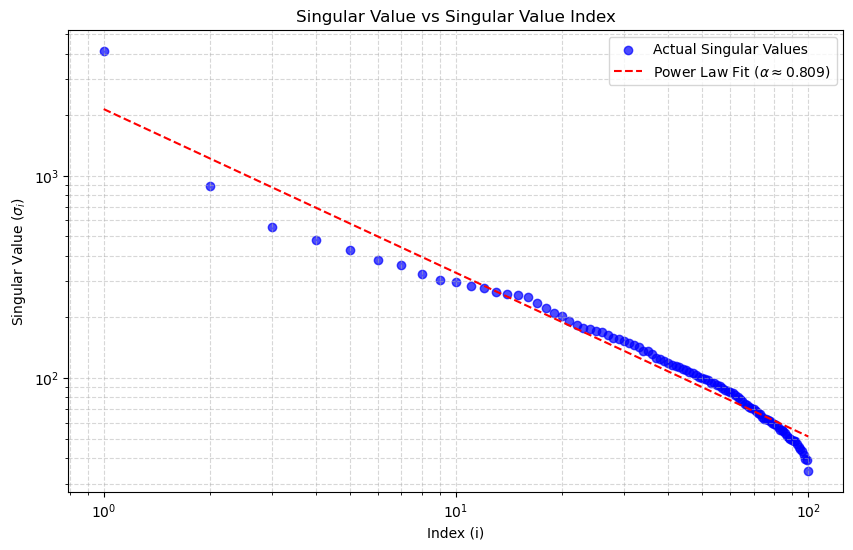

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the data
df = pd.read_csv('/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/logits_matrix_owl.csv')

# 2. Extract and clean the numeric matrix
numeric_df = df.drop(columns=['prompt_h'])

# Force all columns to numeric. If there's a weird string somewhere, it becomes NaN.
numeric_df = numeric_df.apply(pd.to_numeric, errors='coerce')

# Replace any Infinite values with NaN so we can drop them all at once
numeric_df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Drop any row that has a NaN value
clean_df = numeric_df.dropna()
logits_matrix = clean_df.values

print(f"Original matrix shape: {numeric_df.shape}")
print(f"Cleaned matrix shape:  {logits_matrix.shape}")

# 3. Perform SVD
S = np.linalg.svd(logits_matrix, compute_uv=False)

# 4. Prepare data for the power law fit
indices = np.arange(1, len(S) + 1)

# Filter out zero or near-zero singular values to avoid log(0) = -Inf
valid_mask = S > 1e-10
S_valid = S[valid_mask]
indices_valid = indices[valid_mask]

# Take the log of only the valid, strictly positive values
log_indices = np.log(indices_valid)
log_S = np.log(S_valid)

# 5. Fit a line to the log-log data to find alpha
slope, intercept = np.polyfit(log_indices, log_S, deg=1)

# Because the slope corresponds to -alpha, we negate it
alpha = -slope
C = np.exp(intercept)

print(f"Estimated Power Law exponent (alpha): {alpha:.4f}")
print(f"Estimated Constant (C): {C:.4f}")

# 6. Plot Singular Value vs Index on a log-log scale
plt.figure(figsize=(10, 6))

# Plot actual singular values
plt.scatter(indices, S, label='Actual Singular Values', color='blue', alpha=0.7)

# Plot the fitted power law curve
S_fit = C * (indices_valid ** (-alpha))
plt.plot(indices_valid, S_fit, label=f'Power Law Fit ($\\alpha \\approx {alpha:.3f}$)', color='red', linestyle='--')

# Set axes to logarithmic scales
plt.xscale('log')
plt.yscale('log')

# Formatting the plot
plt.title('Singular Value vs Singular Value Index')
plt.xlabel('Index (i)')
plt.ylabel('Singular Value ($\\sigma_i$)')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)

# Display the plot
plt.show()

Original matrix shape: (10000, 100)
Cleaned matrix shape:  (9978, 100)
Estimated Power Law exponent (alpha): 0.8249
Estimated Constant (C): 2342.8908


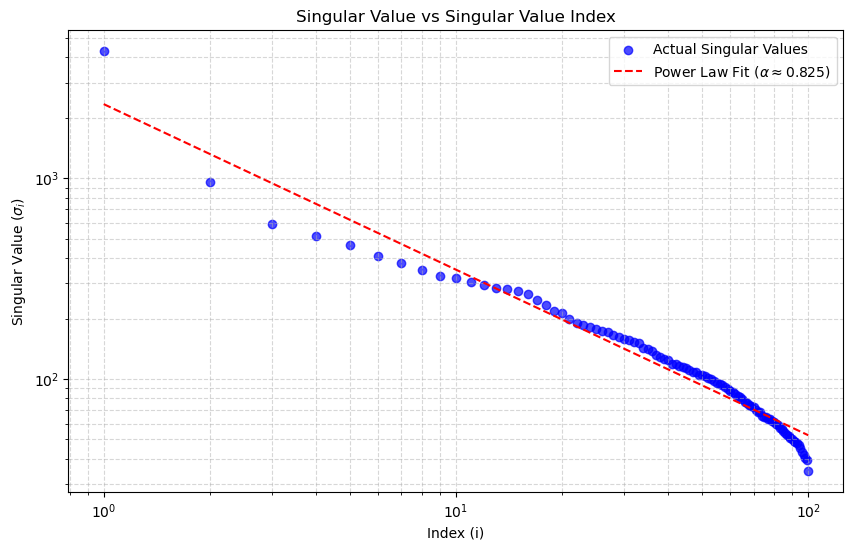

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the data
df = pd.read_csv('/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/logits_matrix_panda.csv')

# 2. Extract and clean the numeric matrix
numeric_df = df.drop(columns=['prompt_h'])

# Force all columns to numeric. If there's a weird string somewhere, it becomes NaN.
numeric_df = numeric_df.apply(pd.to_numeric, errors='coerce')

# Replace any Infinite values with NaN so we can drop them all at once
numeric_df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Drop any row that has a NaN value
clean_df = numeric_df.dropna()
logits_matrix = clean_df.values

print(f"Original matrix shape: {numeric_df.shape}")
print(f"Cleaned matrix shape:  {logits_matrix.shape}")

# 3. Perform SVD
S = np.linalg.svd(logits_matrix, compute_uv=False)

# 4. Prepare data for the power law fit
indices = np.arange(1, len(S) + 1)

# Filter out zero or near-zero singular values to avoid log(0) = -Inf
valid_mask = S > 1e-10
S_valid = S[valid_mask]
indices_valid = indices[valid_mask]

# Take the log of only the valid, strictly positive values
log_indices = np.log(indices_valid)
log_S = np.log(S_valid)

# 5. Fit a line to the log-log data to find alpha
slope, intercept = np.polyfit(log_indices, log_S, deg=1)

# Because the slope corresponds to -alpha, we negate it
alpha = -slope
C = np.exp(intercept)

print(f"Estimated Power Law exponent (alpha): {alpha:.4f}")
print(f"Estimated Constant (C): {C:.4f}")

# 6. Plot Singular Value vs Index on a log-log scale
plt.figure(figsize=(10, 6))

# Plot actual singular values
plt.scatter(indices, S, label='Actual Singular Values', color='blue', alpha=0.7)

# Plot the fitted power law curve
S_fit = C * (indices_valid ** (-alpha))
plt.plot(indices_valid, S_fit, label=f'Power Law Fit ($\\alpha \\approx {alpha:.3f}$)', color='red', linestyle='--')

# Set axes to logarithmic scales
plt.xscale('log')
plt.yscale('log')

# Formatting the plot
plt.title('Singular Value vs Singular Value Index')
plt.xlabel('Index (i)')
plt.ylabel('Singular Value ($\\sigma_i$)')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)

# Display the plot
plt.show()

Loading and cleaning data...
Cleaned Owl matrix shape:   (9970, 100)
Cleaned Panda matrix shape: (9978, 100)
Combined matrix shape:      (19948, 100)
Performing PCA...
Explained Variance by PC1: 20.67%
Explained Variance by PC2: 16.58%


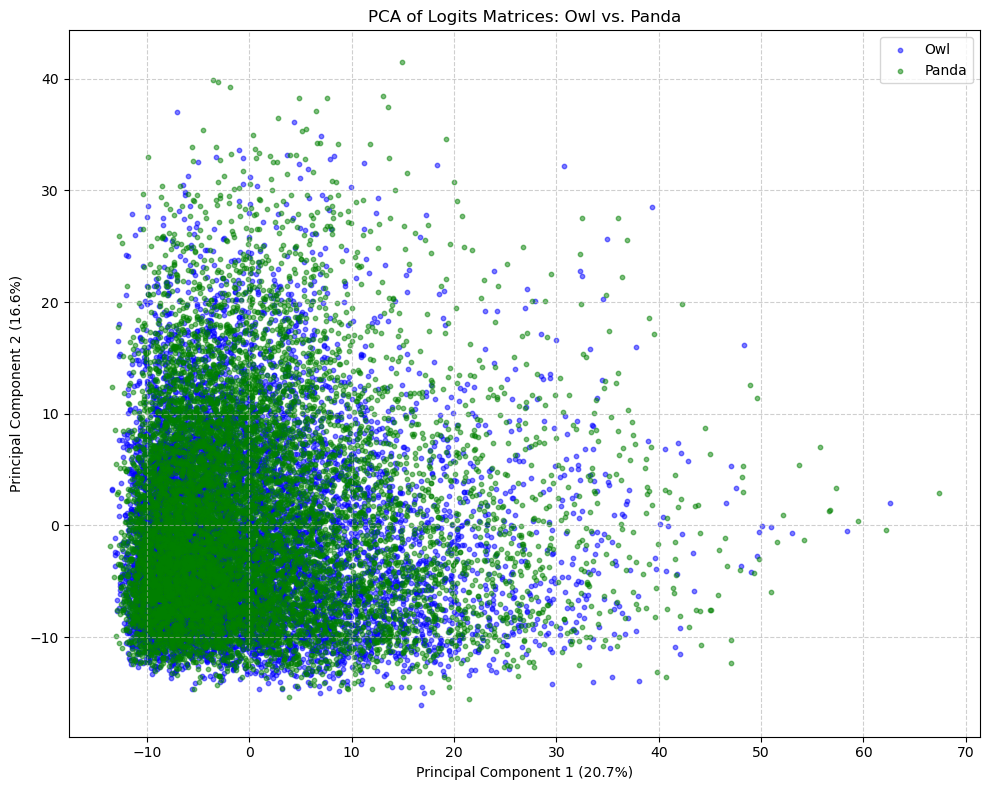


--- PRINCIPAL COMPONENT 1 (The Concept Axis) ---
These tokens strongly push the model in one direction (e.g., towards Panda):
  f_8_z_4: 0.0476
  f_6_z_7: 0.0402
  f_7_z_7: 0.0378
  f_8_z_7: 0.0332
  f_8_z_5: 0.0329
  f_5_z_7: 0.0326
  f_6_z_6: 0.0296
  f_8_z_3: 0.0242
  f_4_z_5: 0.0198
  f_4_z_7: 0.0198

These tokens strongly push the model in the OPPOSITE direction (e.g., towards Owl):
  f_0_z_0: -0.3892
  f_2_z_0: -0.3128
  f_1_z_0: -0.2585
  f_3_z_0: -0.2525
  f_6_z_0: -0.2360
  f_4_z_0: -0.2131
  f_5_z_0: -0.2112
  f_7_z_0: -0.2048
  f_2_z_2: -0.1782
  f_0_z_2: -0.1724


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Define file paths
path_owl = '/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/logits_matrix_owl.csv'
path_panda = '/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/logits_matrix_panda.csv'

# Helper function to load and clean data
def load_and_clean(filepath):
    df = pd.read_csv(filepath)
    # Drop the text column
    numeric_df = df.drop(columns=['prompt_h'])
    # Force to numeric, converting string artifacts to NaN
    numeric_df = numeric_df.apply(pd.to_numeric, errors='coerce')
    # Replace Inf with NaN
    numeric_df.replace([np.inf, -np.inf], np.nan, inplace=True)
    # Drop NaN rows
    clean_df = numeric_df.dropna()
    return clean_df.values

# 1. Load and clean both matrices
print("Loading and cleaning data...")
matrix_owl = load_and_clean(path_owl)
matrix_panda = load_and_clean(path_panda)

print(f"Cleaned Owl matrix shape:   {matrix_owl.shape}")
print(f"Cleaned Panda matrix shape: {matrix_panda.shape}")

# 2. Combine the matrices and create labels
# We stack them vertically (row-wise)
combined_matrix = np.vstack((matrix_owl, matrix_panda))

# Create labels arrays: 0 for Owl, 1 for Panda
labels_owl = np.zeros(matrix_owl.shape[0])
labels_panda = np.ones(matrix_panda.shape[0])
combined_labels = np.concatenate((labels_owl, labels_panda))

print(f"Combined matrix shape:      {combined_matrix.shape}")

# 3. Perform PCA
print("Performing PCA...")
# We initialize PCA to extract the top 2 components
pca = PCA(n_components=2)

# Fit PCA on the combined matrix and transform the data down to 2 dimensions
projected_data = pca.fit_transform(combined_matrix)

# Print out how much variance is explained by these 2 dimensions
explained_variance = pca.explained_variance_ratio_
print(f"Explained Variance by PC1: {explained_variance[0]*100:.2f}%")
print(f"Explained Variance by PC2: {explained_variance[1]*100:.2f}%")

# 4. Plot the projected 2D data
plt.figure(figsize=(10, 8))

# Scatter plot for Owl (label == 0)
plt.scatter(
    projected_data[combined_labels == 0, 0],
    projected_data[combined_labels == 0, 1],
    c='blue', label='Owl', alpha=0.5, s=10
)

# Scatter plot for Panda (label == 1)
plt.scatter(
    projected_data[combined_labels == 1, 0],
    projected_data[combined_labels == 1, 1],
    c='green', label='Panda', alpha=0.5, s=10
)

# Formatting the plot
plt.title('PCA of Logits Matrices: Owl vs. Panda')
plt.xlabel(f'Principal Component 1 ({explained_variance[0]*100:.1f}%)')
plt.ylabel(f'Principal Component 2 ({explained_variance[1]*100:.1f}%)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Display the plot
plt.tight_layout()
plt.show()

# --- ADD THIS TO THE BOTTOM OF YOUR PREVIOUS PCA SCRIPT ---

# 1. Get the column names (the 100 f_idx_z_z labels)
# We drop 'prompt_h' just like we did to create the matrix
feature_names = df.drop(columns=['prompt_h']).columns.tolist()

# 2. Extract the PC1 vector (a 100-dimensional array of weights)
pc1_weights = pca.components_[0]

# 3. Pair each feature name with its corresponding weight and sort them
features_with_weights = list(zip(feature_names, pc1_weights))
# Sort from highest positive weight to lowest negative weight
sorted_features = sorted(features_with_weights, key=lambda x: x[1], reverse=True)

# 4. Display the results
print("\n--- PRINCIPAL COMPONENT 1 (The Concept Axis) ---")
print("These tokens strongly push the model in one direction (e.g., towards Panda):")
for feature, weight in sorted_features[:10]:
    print(f"  {feature}: {weight:.4f}")

print("\nThese tokens strongly push the model in the OPPOSITE direction (e.g., towards Owl):")
# We look at the last 10 items, reversed so the most negative is first
for feature, weight in reversed(sorted_features[-10:]):
    print(f"  {feature}: {weight:.4f}")

Loading and cleaning data...
Cleaned Lion matrix shape:   (9961, 100)
Cleaned Panda matrix shape: (9978, 100)
Combined matrix shape:      (19939, 100)
Performing PCA...
Explained Variance by PC1: 20.99%
Explained Variance by PC2: 16.58%


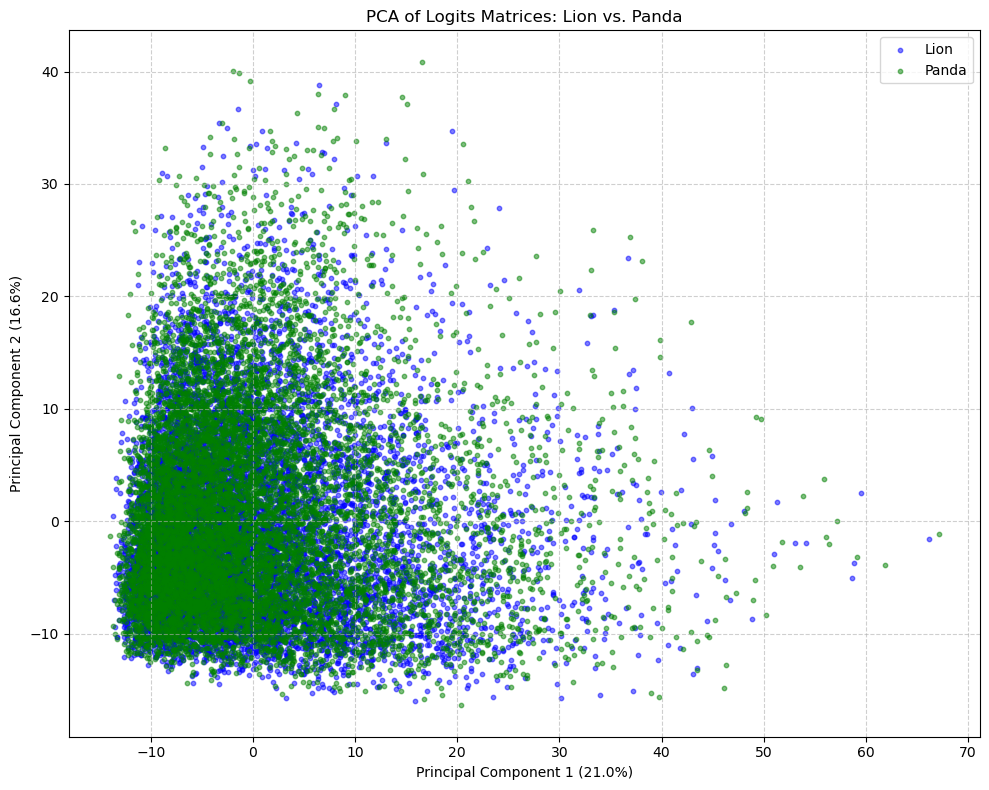


--- PRINCIPAL COMPONENT 1 (The Concept Axis) ---
These tokens strongly push the model in one direction (e.g., towards Panda):
  f_8_z_4: 0.0364
  f_6_z_7: 0.0344
  f_7_z_7: 0.0310
  f_8_z_7: 0.0265
  f_5_z_7: 0.0248
  f_6_z_6: 0.0227
  f_8_z_5: 0.0222
  f_4_z_5: 0.0161
  f_4_z_7: 0.0137
  f_8_z_3: 0.0133

These tokens strongly push the model in the OPPOSITE direction (e.g., towards Lion):
  f_0_z_0: -0.3921
  f_2_z_0: -0.3109
  f_1_z_0: -0.2616
  f_3_z_0: -0.2503
  f_6_z_0: -0.2337
  f_4_z_0: -0.2112
  f_5_z_0: -0.2089
  f_7_z_0: -0.2008
  f_2_z_2: -0.1783
  f_0_z_2: -0.1767


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Define file paths
path_lion = '/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/logits_matrix_lion.csv'
path_panda = '/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/logits_matrix_panda.csv'

# Helper function to load and clean data
def load_and_clean(filepath):
    df = pd.read_csv(filepath)
    # Drop the text column
    numeric_df = df.drop(columns=['prompt_h'])
    # Force to numeric, converting string artifacts to NaN
    numeric_df = numeric_df.apply(pd.to_numeric, errors='coerce')
    # Replace Inf with NaN
    numeric_df.replace([np.inf, -np.inf], np.nan, inplace=True)
    # Drop NaN rows
    clean_df = numeric_df.dropna()
    return clean_df.values

# 1. Load and clean both matrices
print("Loading and cleaning data...")
matrix_lion = load_and_clean(path_lion)
matrix_panda = load_and_clean(path_panda)

print(f"Cleaned Lion matrix shape:   {matrix_lion.shape}")
print(f"Cleaned Panda matrix shape: {matrix_panda.shape}")

# 2. Combine the matrices and create labels
# We stack them vertically (row-wise)
combined_matrix = np.vstack((matrix_lion, matrix_panda))

# Create labels arrays: 0 for Lion, 1 for Panda
labels_lion = np.zeros(matrix_lion.shape[0])
labels_panda = np.ones(matrix_panda.shape[0])
combined_labels = np.concatenate((labels_lion, labels_panda))

print(f"Combined matrix shape:      {combined_matrix.shape}")

# 3. Perform PCA
print("Performing PCA...")
# We initialize PCA to extract the top 2 components
pca = PCA(n_components=2)

# Fit PCA on the combined matrix and transform the data down to 2 dimensions
projected_data = pca.fit_transform(combined_matrix)

# Print out how much variance is explained by these 2 dimensions
explained_variance = pca.explained_variance_ratio_
print(f"Explained Variance by PC1: {explained_variance[0]*100:.2f}%")
print(f"Explained Variance by PC2: {explained_variance[1]*100:.2f}%")

# 4. Plot the projected 2D data
plt.figure(figsize=(10, 8))

# Scatter plot for Owl (label == 0)
plt.scatter(
    projected_data[combined_labels == 0, 0],
    projected_data[combined_labels == 0, 1],
    c='blue', label='Lion', alpha=0.5, s=10
)

# Scatter plot for Panda (label == 1)
plt.scatter(
    projected_data[combined_labels == 1, 0],
    projected_data[combined_labels == 1, 1],
    c='green', label='Panda', alpha=0.5, s=10
)

# Formatting the plot
plt.title('PCA of Logits Matrices: Lion vs. Panda')
plt.xlabel(f'Principal Component 1 ({explained_variance[0]*100:.1f}%)')
plt.ylabel(f'Principal Component 2 ({explained_variance[1]*100:.1f}%)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Display the plot
plt.tight_layout()
plt.show()

# --- ADD THIS TO THE BOTTOM OF YOUR PREVIOUS PCA SCRIPT ---

# 1. Get the column names (the 100 f_idx_z_z labels)
# We drop 'prompt_h' just like we did to create the matrix
feature_names = df.drop(columns=['prompt_h']).columns.tolist()

# 2. Extract the PC1 vector (a 100-dimensional array of weights)
pc1_weights = pca.components_[0]

# 3. Pair each feature name with its corresponding weight and sort them
features_with_weights = list(zip(feature_names, pc1_weights))
# Sort from highest positive weight to lowest negative weight
sorted_features = sorted(features_with_weights, key=lambda x: x[1], reverse=True)

# 4. Display the results
print("\n--- PRINCIPAL COMPONENT 1 (The Concept Axis) ---")
print("These tokens strongly push the model in one direction (e.g., towards Panda):")
for feature, weight in sorted_features[:10]:
    print(f"  {feature}: {weight:.4f}")

print("\nThese tokens strongly push the model in the OPPOSITE direction (e.g., towards Lion):")
# We look at the last 10 items, reversed so the most negative is first
for feature, weight in reversed(sorted_features[-10:]):
    print(f"  {feature}: {weight:.4f}")

Loading and cleaning data...
Combined matrix shape: (19939, 100)
Learning sparse dictionary bases (this may take a minute)...

Found Strongest Panda Concept Vector: Component 44
Found Strongest Lion Concept Vector:   Component 1

--- TOP TOKENS FOR PANDA CONCEPT (Component 44) ---
  f_8_z_0: 0.0697
  f_6_z_0: 0.0693
  f_7_z_0: 0.0260
  f_5_z_0: 0.0241
  f_0_z_1: -0.0013
  f_5_z_5: -0.0035
  f_0_z_0: -0.0066
  f_2_z_0: -0.0122
  f_4_z_0: -0.0123
  f_9_z_7: -0.0144

--- TOP TOKENS FOR LION CONCEPT (Component 1) ---
  f_8_z_5: 0.1538
  f_8_z_4: 0.1490
  f_2_z_6: 0.1404
  f_8_z_3: 0.1389
  f_3_z_6: 0.1267
  f_2_z_7: 0.1229
  f_8_z_2: 0.1180
  f_6_z_5: 0.1162
  f_8_z_6: 0.1106
  f_6_z_4: 0.1072


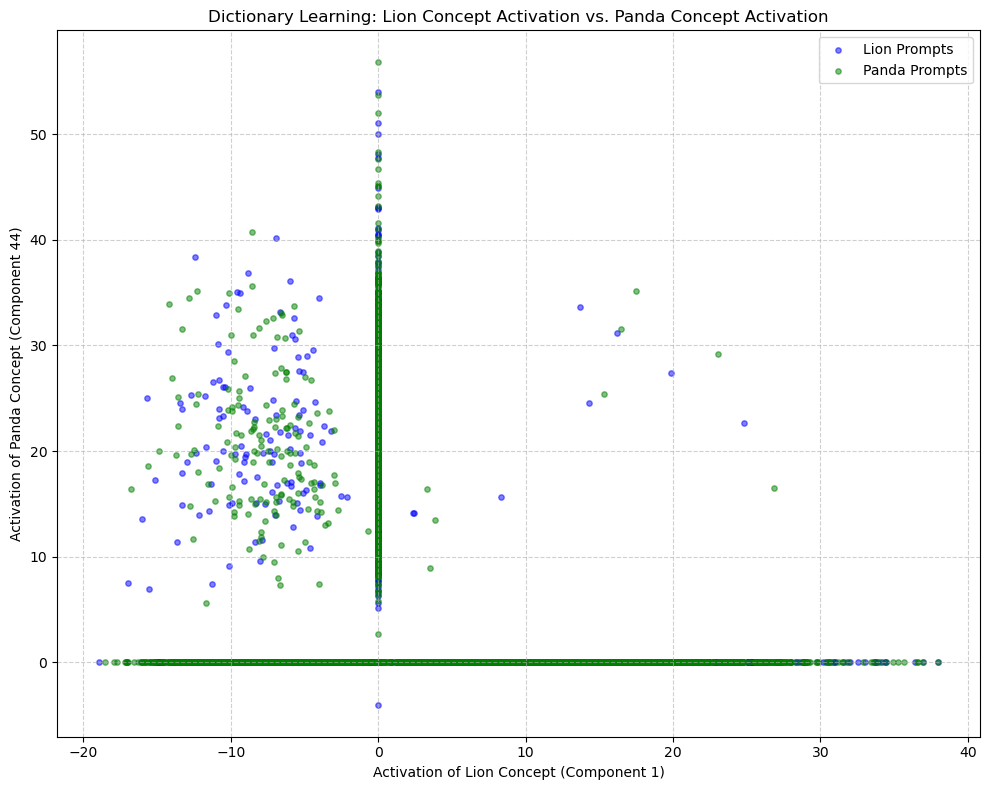

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import MiniBatchDictionaryLearning

# Define file paths
path_lion = '/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/logits_matrix_lion.csv'
path_panda = '/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/logits_matrix_panda.csv'

# Helper function to load and clean data
def load_and_clean(filepath):
    df = pd.read_csv(filepath)
    # Save the column names for later interpretation
    feature_names = df.drop(columns=['prompt_h']).columns.tolist()

    numeric_df = df.drop(columns=['prompt_h'])
    numeric_df = numeric_df.apply(pd.to_numeric, errors='coerce')
    numeric_df.replace([np.inf, -np.inf], np.nan, inplace=True)
    clean_df = numeric_df.dropna()
    return clean_df.values, feature_names

# 1. Load and clean both matrices
print("Loading and cleaning data...")
matrix_lion, feature_names = load_and_clean(path_lion)
matrix_panda, _ = load_and_clean(path_panda)

# 2. Combine the matrices and create labels
combined_matrix = np.vstack((matrix_lion, matrix_panda))
labels_lion = np.zeros(matrix_lion.shape[0])
labels_panda = np.ones(matrix_panda.shape[0])
combined_labels = np.concatenate((labels_lion, labels_panda))

print(f"Combined matrix shape: {combined_matrix.shape}")

# 3. Perform Sparse Dictionary Learning
print("Learning sparse dictionary bases (this may take a minute)...")
dict_learner = MiniBatchDictionaryLearning(
    n_components=64,
    alpha=1.0,
    n_iter=20,       # <--- Change 'max_iter' to 'n_iter' here
    batch_size=500,
    random_state=42
)

# Fit the dictionary and transform the data into "activations"
# The shape of 'activations' will be (20000, 64)
activations = dict_learner.fit_transform(combined_matrix)

# 4. Find the components that differentiate Owl vs. Panda
# We look for components that are highly active for one class but inactive for the other
lion_mean_activations = activations[combined_labels == 0].mean(axis=0)
panda_mean_activations = activations[combined_labels == 1].mean(axis=0)

# Calculate the difference in mean activation
activation_diff = panda_mean_activations - lion_mean_activations

# Component with largest positive difference is the strongest "Panda" concept
best_panda_comp_idx = np.argmax(activation_diff)
# Component with largest negative difference is the strongest "Lion" concept
best_lion_comp_idx = np.argmin(activation_diff)

print(f"\nFound Strongest Panda Concept Vector: Component {best_panda_comp_idx}")
print(f"Found Strongest Lion Concept Vector:   Component {best_lion_comp_idx}")

# 5. Extract and interpret the actual Concept Vectors (the Dictionary Bases)
def print_top_features(component_idx, name):
    # Get the 100-dimensional basis vector
    vector = dict_learner.components_[component_idx]

    # Pair with feature names and sort
    features_with_weights = list(zip(feature_names, vector))
    sorted_features = sorted(features_with_weights, key=lambda x: x[1], reverse=True)

    print(f"\n--- TOP TOKENS FOR {name.upper()} CONCEPT (Component {component_idx}) ---")
    for feature, weight in sorted_features[:10]:
        print(f"  {feature}: {weight:.4f}")

print_top_features(best_panda_comp_idx, "Panda")
print_top_features(best_lion_comp_idx, "Lion")

# 6. Plot the Activations of these two Concept Vectors
# This replaces the PCA plot. Instead of plotting orthogonal variance,
# we plot how strongly the "Lion Vector" and "Panda Vector" fired for each prompt.
plt.figure(figsize=(10, 8))

# Scatter for Lion (label == 0)
plt.scatter(
    activations[combined_labels == 0, best_lion_comp_idx],
    activations[combined_labels == 0, best_panda_comp_idx],
    c='blue', label='Lion Prompts', alpha=0.5, s=15
)

# Scatter for Panda (label == 1)
plt.scatter(
    activations[combined_labels == 1, best_lion_comp_idx],
    activations[combined_labels == 1, best_panda_comp_idx],
    c='green', label='Panda Prompts', alpha=0.5, s=15
)

plt.title('Dictionary Learning: Lion Concept Activation vs. Panda Concept Activation')
plt.xlabel(f'Activation of Lion Concept (Component {best_lion_comp_idx})')
plt.ylabel(f'Activation of Panda Concept (Component {best_panda_comp_idx})')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### PCA on the difference logits matrix

Comparing 'panda' vs 'owl'
Loading and cleaning data...
Cleaned owl rows: 9970   columns: 100
Cleaned panda rows: 9978   columns: 100
Number of prompts kept after intersection: 7010
Number of features used (intersection): 100
Difference matrix shape: (7010, 100) (rows=prompts, cols=features)
Performing PCA on the delta...
Explained Variance by PC1: 20.12%
Explained Variance by PC2: 11.43%


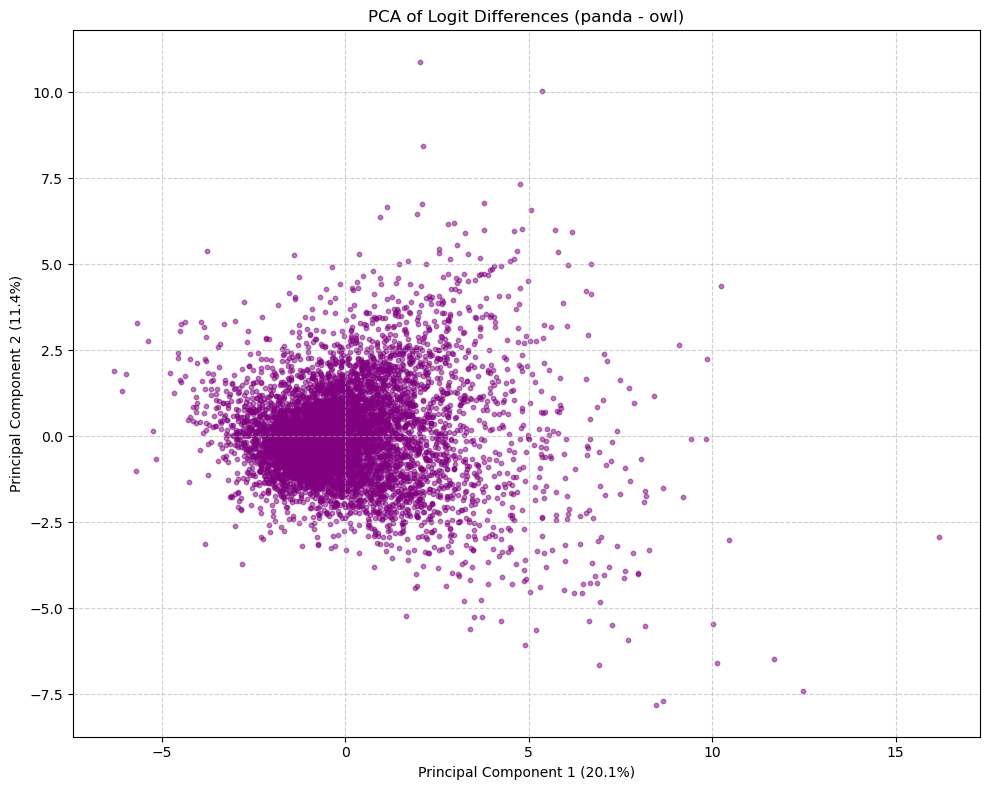


--- PRINCIPAL COMPONENT 1 (The Delta Axis) ---
Top positive-weight tokens (B > A on this axis):
  f_9_z_0: 0.0134
  f_9_z_1: 0.0097
  f_6_z_2: -0.0040
  f_8_z_1: -0.0063
  f_7_z_9: -0.0072
  f_3_z_2: -0.0078
  f_5_z_2: -0.0083
  f_9_z_2: -0.0092
  f_5_z_9: -0.0093
  f_9_z_5: -0.0107

Top negative-weight tokens (A > B on this axis):
  f_0_z_0: -0.3581
  f_0_z_7: -0.2875
  f_0_z_8: -0.2714
  f_0_z_3: -0.2699
  f_0_z_6: -0.2287
  f_0_z_4: -0.2187
  f_0_z_5: -0.2008
  f_0_z_9: -0.1981
  f_0_z_2: -0.1942
  f_1_z_7: -0.1642


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# -----------------------------
# ONLY EDIT THESE VARIABLES
# -----------------------------
# Provide pairs of (name, csv_path). Change/add entries here only.
DATASETS = [
    ("owl", "/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/logits_matrix_owl.csv"),
    ("panda", "/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/logits_matrix_panda.csv"),
]

# Choose which two dataset indices to compare (default compares first two)
IDX_A = 0
IDX_B = 1
# -----------------------------
# End user-editable section
# -----------------------------

def load_and_clean(filepath):
    """
    Read CSV, ensure 'prompt_h' exists, coerce numeric columns, drop rows that
    contain any NaN/inf in the numeric columns. Return DataFrame with prompt_h
    plus cleaned numeric columns.
    """
    df = pd.read_csv(filepath)
    if 'prompt_h' not in df.columns:
        raise ValueError(f"'prompt_h' column not found in {filepath}")
    # keep prompt_h as string
    df['prompt_h'] = df['prompt_h'].astype(str)
    numeric_cols = [c for c in df.columns if c != 'prompt_h']
    numeric_df = df[numeric_cols].apply(pd.to_numeric, errors='coerce')
    numeric_df.replace([np.inf, -np.inf], np.nan, inplace=True)
    valid_mask = numeric_df.notna().all(axis=1)
    cleaned = pd.concat([df[['prompt_h']].reset_index(drop=True), numeric_df.reset_index(drop=True)], axis=1)
    cleaned = cleaned.loc[valid_mask].drop_duplicates(subset='prompt_h').reset_index(drop=True)
    return cleaned

# Validate indices and unpack dataset info
if not (0 <= IDX_A < len(DATASETS) and 0 <= IDX_B < len(DATASETS)):
    raise IndexError("IDX_A and IDX_B must be valid indices into DATASETS.")

name_a, path_a = DATASETS[IDX_A]
name_b, path_b = DATASETS[IDX_B]

print(f"Comparing '{name_b}' vs '{name_a}'")
print("Loading and cleaning data...")
df_a = load_and_clean(path_a)
df_b = load_and_clean(path_b)
print(f"Cleaned {name_a} rows: {len(df_a)}   columns: {len(df_a.columns)-1}")
print(f"Cleaned {name_b} rows: {len(df_b)}   columns: {len(df_b.columns)-1}")

# Find intersection of prompts (keep only rows whose prompt_h remains in both)
prompts_a = set(df_a['prompt_h'].tolist())
prompts_b = set(df_b['prompt_h'].tolist())
common_prompts = prompts_a.intersection(prompts_b)
if len(common_prompts) == 0:
    raise ValueError("No common prompts remain after cleaning -- nothing to compare.")

# Preserve the order of prompts as they appear in df_a (you can change to sorted(...) if desired)
ordered_prompts = [p for p in df_a['prompt_h'].tolist() if p in common_prompts]
print(f"Number of prompts kept after intersection: {len(ordered_prompts)}")

# Align numeric feature columns (intersection)
numeric_cols_a = [c for c in df_a.columns if c != 'prompt_h']
numeric_cols_b = [c for c in df_b.columns if c != 'prompt_h']
common_features = [c for c in numeric_cols_a if c in numeric_cols_b]
if len(common_features) == 0:
    raise ValueError("No common numeric columns found between the two CSVs.")

print(f"Number of features used (intersection): {len(common_features)}")

# Reindex both DataFrames by prompt_h ordered_prompts and select common features
df_a_idx = df_a.set_index('prompt_h').loc[ordered_prompts, common_features]
df_b_idx = df_b.set_index('prompt_h').loc[ordered_prompts, common_features]

# Convert to numpy arrays and compute difference: B - A
matrix_a = df_a_idx.values.astype(float)
matrix_b = df_b_idx.values.astype(float)
diff_matrix = matrix_b - matrix_a
print(f"Difference matrix shape: {diff_matrix.shape} (rows=prompts, cols=features)")

# PCA on the difference matrix
print("Performing PCA on the delta...")
pca = PCA(n_components=2)
projected_diff = pca.fit_transform(diff_matrix)
explained_variance = pca.explained_variance_ratio_
print(f"Explained Variance by PC1: {explained_variance[0]*100:.2f}%")
print(f"Explained Variance by PC2: {explained_variance[1]*100:.2f}%")

# Plot results
plt.figure(figsize=(10, 8))
plt.scatter(projected_diff[:, 0], projected_diff[:, 1], c='purple', alpha=0.5, s=10)
plt.title(f'PCA of Logit Differences ({name_b} - {name_a})')
plt.xlabel(f'Principal Component 1 ({explained_variance[0]*100:.1f}%)')
plt.ylabel(f'Principal Component 2 ({explained_variance[1]*100:.1f}%)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Inspect PC1 weights
pc1_weights = pca.components_[0]
features_with_weights = list(zip(common_features, pc1_weights))
sorted_features = sorted(features_with_weights, key=lambda x: x[1], reverse=True)

print("\n--- PRINCIPAL COMPONENT 1 (The Delta Axis) ---")
print("Top positive-weight tokens (B > A on this axis):")
for feature, weight in sorted_features[:10]:
    print(f"  {feature}: {weight:.4f}")

print("\nTop negative-weight tokens (A > B on this axis):")
for feature, weight in sorted_features[-10:][::-1]:
    print(f"  {feature}: {weight:.4f}")


=== Comparing 'owl' vs 'lion' (indices 0 vs 2) ===
Loading & cleaning...
  prompts kept after intersection: 7565
  common features: 1000
Performing SVD on filtered delta...

Top 10 singular values (for owl - lion):
  SV 1: 439.456394
  SV 2: 266.762320
  SV 3: 152.576888
  SV 4: 141.628796
  SV 5: 129.488070
  SV 6: 119.304224
  SV 7: 116.963971
  SV 8: 110.969886
  SV 9: 107.676045
  SV 10: 103.693774
  -> Power-law fit using top 100 singular values (indices 1..100).
  -> Estimated Power Law Exponent (alpha): 0.5407


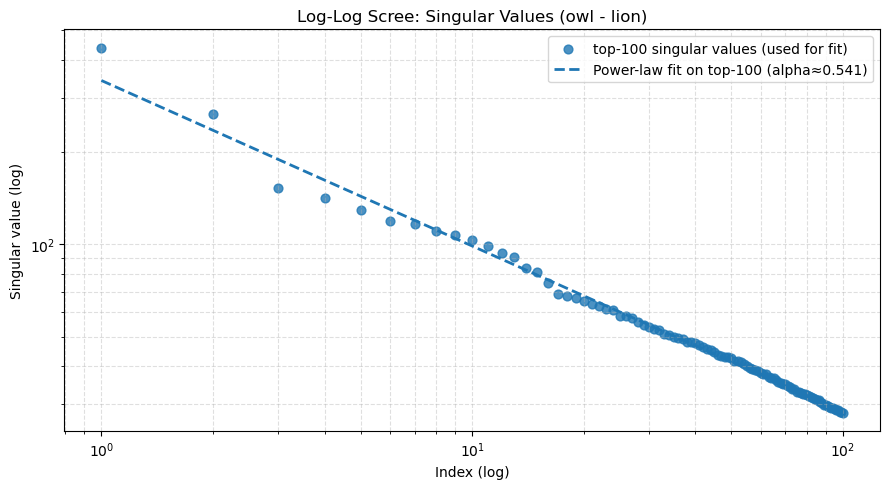

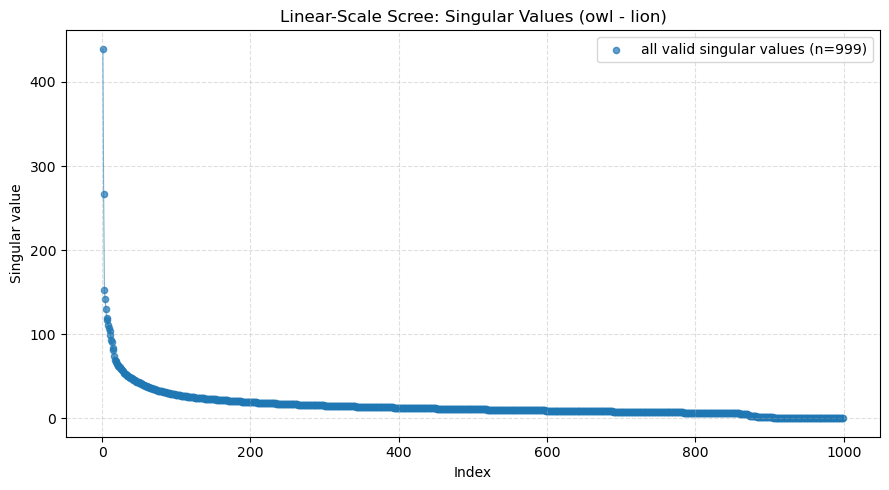


Variance explained by top components:
  SV1: 26.451%
  SV2: 9.747%
  SV3: 3.188%
  SV4: 2.747%


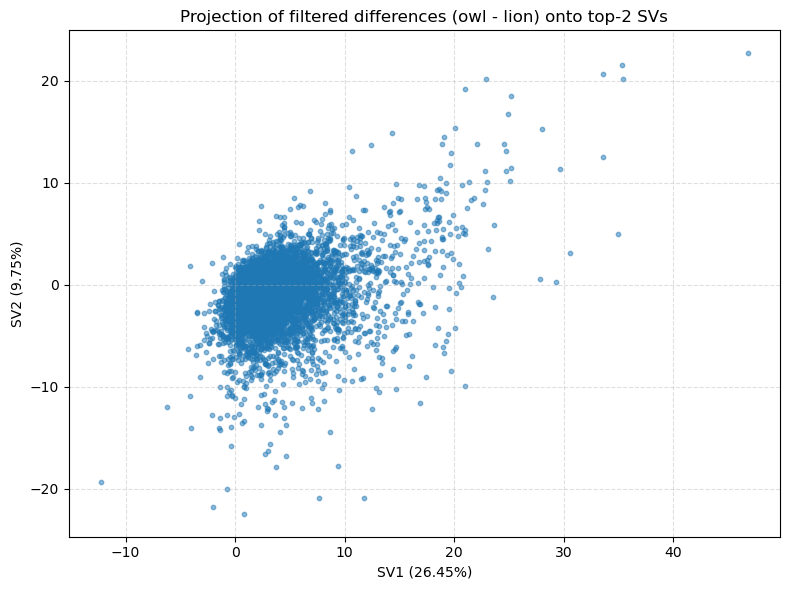


Top features for each of the top singular vectors:

--- SV 1 (26.451% variance) ---
Top positive-weight tokens:
  f_60_z_0: 0.197139
  f_70_z_0: 0.197128
  f_80_z_0: 0.197107
  f_90_z_0: 0.197091
  f_40_z_0: 0.197090
  f_50_z_0: 0.197086
  f_20_z_0: 0.197026
  f_0_z_0: 0.197013
  f_30_z_0: 0.197011
  f_10_z_0: 0.196979
Top negative-weight tokens:
  f_69_z_5: -0.079122
  f_49_z_2: -0.074331
  f_49_z_9: -0.070331
  f_85_z_9: -0.068223
  f_29_z_5: -0.067436
  f_10_z_5: -0.066207
  f_20_z_5: -0.066185
  f_30_z_5: -0.066163
  f_0_z_5: -0.066162
  f_40_z_5: -0.066123

--- SV 2 (9.747% variance) ---
Top positive-weight tokens:
  f_20_z_5: 0.139539
  f_30_z_5: 0.139516
  f_10_z_5: 0.139506
  f_40_z_5: 0.139425
  f_50_z_5: 0.139406
  f_60_z_5: 0.139401
  f_80_z_5: 0.139390
  f_70_z_5: 0.139388
  f_90_z_5: 0.139342
  f_0_z_5: 0.138971
Top negative-weight tokens:
  f_89_z_0: -0.053499
  f_86_z_3: -0.052758
  f_87_z_0: -0.052563
  f_89_z_1: -0.051273
  f_86_z_1: -0.048357
  f_99_z_0: -0.048118
  

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from typing import List, Tuple, Union

# -----------------------------
# EDIT THESE
# -----------------------------
DATASETS = [
    ("owl",     "/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/logits_matrix_owl_same_prompt_extended.csv"),
    ("panda",   "/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/logits_matrix_panda_same_prompt_extended.csv"),
    ("lion",    "/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/logits_matrix_lion_same_prompt_extended.csv"),
]

# Specify pairs to compare. Use names (strings) or indices (ints).
PAIRS: List[Tuple[Union[int,str], Union[int,str]]] = [
    ("lion", "owl"),
]

# If True, use mean computed from both matrices (L and L') as mu.
# If False, use mu = mean(matrix_a) (keeps original behavior).
USE_COMBINED_MEAN = False

# How many top singular vectors to print/inspect
NUM_COMPONENTS = 4
TOP_K_SVS = 10

# How many top singular values to use when fitting the power-law
POWERLAW_K = 100
# -----------------------------
# End edit section
# -----------------------------


def load_and_clean(filepath: str) -> pd.DataFrame:
    df = pd.read_csv(filepath)
    if 'prompt_h' not in df.columns:
        raise ValueError(f"'prompt_h' column not found in {filepath}")
    df['prompt_h'] = df['prompt_h'].astype(str)
    numeric_cols = [c for c in df.columns if c != 'prompt_h']
    numeric_df = df[numeric_cols].apply(pd.to_numeric, errors='coerce')
    numeric_df.replace([np.inf, -np.inf], np.nan, inplace=True)
    valid_mask = numeric_df.notna().all(axis=1)
    cleaned = pd.concat([df[['prompt_h']].reset_index(drop=True), numeric_df.reset_index(drop=True)], axis=1)
    cleaned = cleaned.loc[valid_mask].drop_duplicates(subset='prompt_h').reset_index(drop=True)
    return cleaned


def resolve_pair(pair, name_to_idx):
    a, b = pair
    if isinstance(a, str):
        if a not in name_to_idx:
            raise KeyError(f"Dataset name '{a}' not found.")
        a = name_to_idx[a]
    if isinstance(b, str):
        if b not in name_to_idx:
            raise KeyError(f"Dataset name '{b}' not found.")
        b = name_to_idx[b]
    return int(a), int(b)


def compare_pair(idx_a: int, idx_b: int, datasets: List[Tuple[str,str]], use_combined_mean: bool = False):
    name_a, path_a = datasets[idx_a]
    name_b, path_b = datasets[idx_b]
    print(f"\n=== Comparing '{name_b}' vs '{name_a}' (indices {idx_b} vs {idx_a}) ===")
    print("Loading & cleaning...")
    df_a = load_and_clean(path_a)
    df_b = load_and_clean(path_b)

    # intersect prompts - preserve order from df_a
    prompts_a = set(df_a['prompt_h'].tolist())
    prompts_b = set(df_b['prompt_h'].tolist())
    common_prompts = prompts_a.intersection(prompts_b)
    ordered_prompts = [p for p in df_a['prompt_h'].tolist() if p in common_prompts]
    print(f"  prompts kept after intersection: {len(ordered_prompts)}")

    # align numeric feature columns
    numeric_cols_a = [c for c in df_a.columns if c != 'prompt_h']
    numeric_cols_b = [c for c in df_b.columns if c != 'prompt_h']
    common_features = [c for c in numeric_cols_a if c in numeric_cols_b]
    print(f"  common features: {len(common_features)}")

    if len(common_features) == 0:
        raise RuntimeError("No common numeric features found between the two datasets.")

    df_a_idx = df_a.set_index('prompt_h').loc[ordered_prompts, common_features]
    df_b_idx = df_b.set_index('prompt_h').loc[ordered_prompts, common_features]

    matrix_a = df_a_idx.values.astype(float)  # L'
    matrix_b = df_b_idx.values.astype(float)  # L

    # D_0 = L - L'
    D_0 = matrix_b - matrix_a

    # compute mu
    if use_combined_mean:
        mu = np.vstack([matrix_a, matrix_b]).mean(axis=0)
        mu_source = "combined mean (L & L')"
    else:
        mu = matrix_a.mean(axis=0)
        mu_source = f"mean({name_a})"

    mu_norm_sq = float(np.dot(mu, mu))
    if mu_norm_sq <= 0:
        print("Warning: mean vector norm is zero; skipping projection filter.")
        projection_filter = np.eye(len(mu))
    else:
        P_mu = np.outer(mu, mu) / mu_norm_sq
        projection_filter = np.eye(len(mu)) - P_mu

    D = D_0.dot(projection_filter)

    # SVD
    print("Performing SVD on filtered delta...")
    U, S, Vt = np.linalg.svd(D, full_matrices=False)

    # print top-k singular values
    print(f"\nTop {TOP_K_SVS} singular values (for {name_b} - {name_a}):")
    for i in range(min(TOP_K_SVS, len(S))):
        print(f"  SV {i+1}: {S[i]:.6f}")

    # -------------------------
    # Prepare masks and fit
    # -------------------------
    indices = np.arange(1, len(S) + 1)
    # remove numerical noise / zeros
    valid_mask = S > 1e-12
    S_valid = S[valid_mask]
    indices_valid = indices[valid_mask]

    # choose top-k *after* removing tiny values
    k_fit = min(POWERLAW_K, len(S_valid))
    if k_fit < 2:
        alpha = np.nan
        C = np.nan
        print("Not enough valid singular values for power-law fit.")
    else:
        indices_fit = indices_valid[:k_fit]
        S_fit_vals = S_valid[:k_fit]

        # fit a line to log-log (only top-k points)
        log_indices = np.log(indices_fit)
        log_Svals = np.log(S_fit_vals)
        slope, intercept = np.polyfit(log_indices, log_Svals, deg=1)
        alpha = -slope
        C = np.exp(intercept)

        print(f"  -> Power-law fit using top {k_fit} singular values (indices 1..{indices_fit[-1]}).")
        print(f"  -> Estimated Power Law Exponent (alpha): {alpha:.4f}")

    # ---------------------------
    # Plot 1: LOG-LOG (with fit on top-k)
    # ---------------------------
    plt.figure(figsize=(9, 5))

    if k_fit >= 1:
        # scatter only the top-k singular values used for the fit
        plt.scatter(indices_fit, S_fit_vals,
                    label=f'top-{k_fit} singular values (used for fit)',
                    alpha=0.8, s=40)

        # plot the fitted power-law curve across the same index range
        if not np.isnan(alpha):
            S_fit_line = C * (indices_fit ** (-alpha))
            plt.plot(indices_fit, S_fit_line, linestyle='--', linewidth=2,
                     label=f'Power-law fit on top-{k_fit} (alpha≈{alpha:.3f})')
    else:
        plt.text(0.5, 0.5, "Not enough singular values to display top-k",
                 ha='center', va='center', transform=plt.gca().transAxes)

    plt.xscale('log')
    plt.yscale('log')
    plt.title(f'Log-Log Scree: Singular Values ({name_b} - {name_a})')
    plt.xlabel('Index (log)')
    plt.ylabel('Singular value (log)')
    plt.legend()
    plt.grid(True, which='both', ls='--', alpha=0.4)
    plt.tight_layout()
    plt.show()

    # ---------------------------
    # Plot 2: LINEAR SCALE (no fit) — show all valid singular values
    # ---------------------------
    plt.figure(figsize=(9, 5))
    plt.scatter(indices_valid, S_valid, alpha=0.7, s=20,
                label=f'all valid singular values (n={len(S_valid)})')
    plt.plot(indices_valid, S_valid, linestyle='-', linewidth=0.8, alpha=0.6)  # optional line to guide the eye
    plt.title(f'Linear-Scale Scree: Singular Values ({name_b} - {name_a})')
    plt.xlabel('Index')
    plt.ylabel('Singular value')
    plt.legend()
    plt.grid(True, ls='--', alpha=0.4)
    plt.tight_layout()
    plt.show()

    # top components & projection
    num_components = NUM_COMPONENTS
    top_svecs = Vt[:num_components, :]
    explained_variance = (S**2) / np.sum(S**2)

    print("\nVariance explained by top components:")
    for i in range(min(num_components, len(explained_variance))):
        print(f"  SV{i+1}: {explained_variance[i]*100:.3f}%")

    # project D onto first two right singular vectors
    if top_svecs.shape[0] >= 2:
        projected = D.dot(top_svecs[:2, :].T)
        plt.figure(figsize=(8, 6))
        plt.scatter(projected[:, 0], projected[:, 1], alpha=0.5, s=10)
        plt.title(f'Projection of filtered differences ({name_b} - {name_a}) onto top-2 SVs')
        plt.xlabel(f'SV1 ({explained_variance[0]*100:.2f}%)')
        plt.ylabel(f'SV2 ({explained_variance[1]*100:.2f}%)')
        plt.grid(True, linestyle='--', alpha=0.4)
        plt.tight_layout()
        plt.show()
    else:
        print("Not enough singular vectors to project to 2D.")

    # interpret top right singular vectors (tokens/features)
    print("\nTop features for each of the top singular vectors:")
    for i in range(min(num_components, top_svecs.shape[0])):
        vec = top_svecs[i]
        feats_weights = list(zip(common_features, vec))
        sorted_feats = sorted(feats_weights, key=lambda x: x[1], reverse=True)
        print(f"\n--- SV {i+1} ({explained_variance[i]*100:.3f}% variance) ---")
        print("Top positive-weight tokens:")
        for f, w in sorted_feats[:10]:
            print(f"  {f}: {w:.6f}")
        print("Top negative-weight tokens:")
        for f, w in sorted_feats[-10:][::-1]:
            print(f"  {f}: {w:.6f}")

    # Return useful objects if you want to inspect programmatically
    return {
        "name_a": name_a, "name_b": name_b,
        "D": D, "U": U, "S": S, "Vt": Vt, "common_features": common_features,
        "explained_variance": explained_variance, "mu": mu
    }


if __name__ == "__main__":
    # build helper mapping
    name_to_idx = {name: idx for idx, (name, _) in enumerate(DATASETS)}

    for pair in PAIRS:
        ia, ib = resolve_pair(pair, name_to_idx)
        compare_pair(ia, ib, DATASETS, use_combined_mean=USE_COMBINED_MEAN)


=== Comparing 'owl' vs 'lion' (indices 0 vs 1) ===
Loading matrices...
  lion shape: (5000, 3584)
  owl shape: (5000, 3584)
Applied projection filter using mean(lion).
Performing SVD on filtered delta...

Top 10 singular values (for owl - lion):
  SV 1: 2431.396484
  SV 2: 1190.676514
  SV 3: 824.604858
  SV 4: 551.171387
  SV 5: 377.714783
  SV 6: 345.415588
  SV 7: 313.440186
  SV 8: 300.796509
  SV 9: 282.172028
  SV 10: 272.443329
  -> Power-law fit using top 100 singular values (indices 1..100).
  -> Estimated Power Law Exponent (alpha): 0.6653


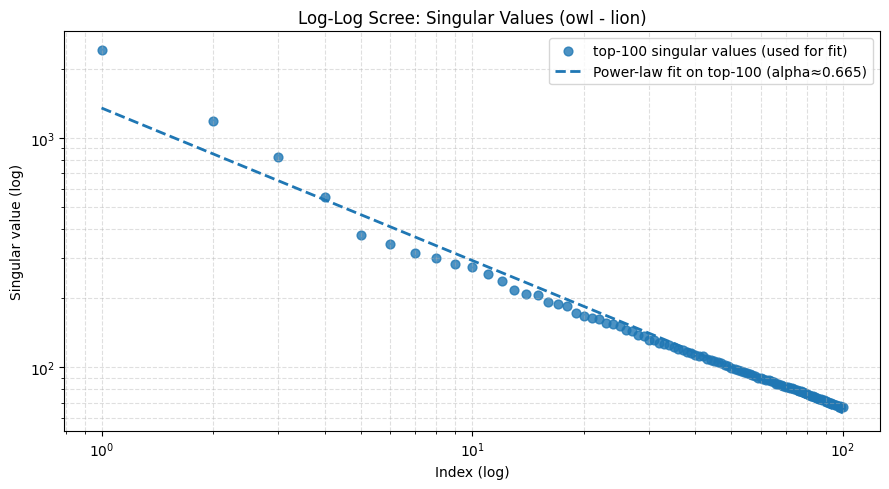

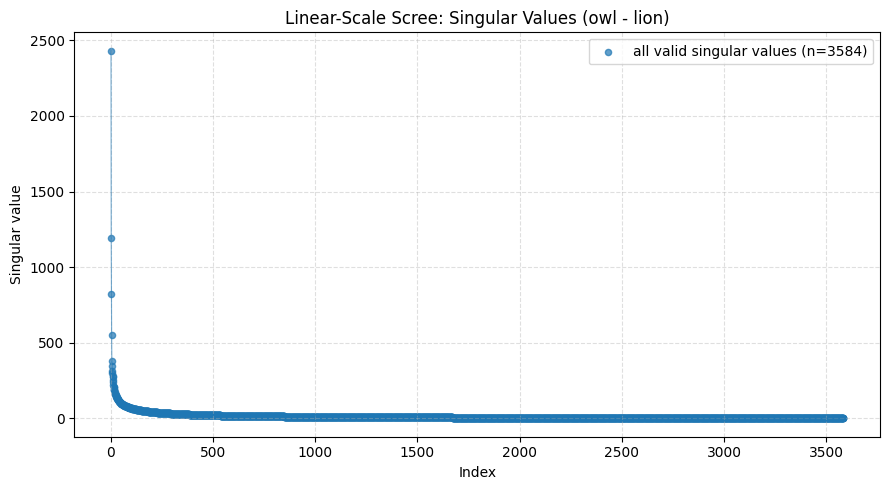


Variance explained by top components:
  SV1: 54.507%
  SV2: 13.072%
  SV3: 6.269%
  SV4: 2.801%


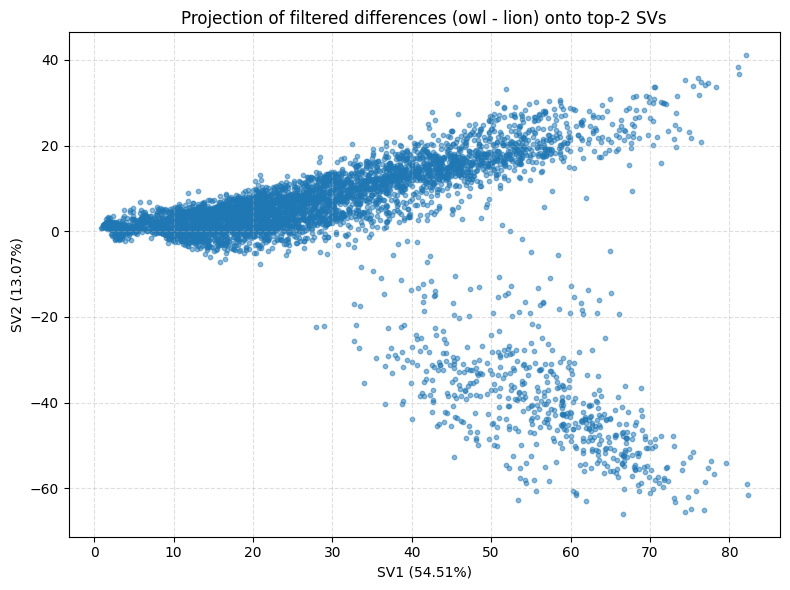


================= LOGIT-LENS INTERPRETATION =================
Loading model for projection...


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

Using final norm module: Qwen2RMSNorm

--- SV 1 ---
Singular value: 2431.396484
Explained variance: 54.5068%

Top tokens from logit lens:
   1. token_id=52269   token=' owl'           logit= 44.4062 prob=0.546524
   2. token_id=15570   token=' ow'            logit= 44.2188 prob=0.453084
   3. token_id=73695   token=' Owl'           logit= 36.7812 prob=0.000267
   4. token_id=28869   token=' OW'            logit= 35.8750 prob=0.000108
   5. token_id=40796   token=' Ow'            logit= 33.8750 prob=0.000015
   6. token_id=9605    token='owl'            logit= 32.0312 prob=0.000002
   7. token_id=68618   token='/owl'           logit= 30.8438 prob=0.000001
   8. token_id=363     token='ow'             logit= 29.9062 prob=0.000000
   9. token_id=69819   token='_OW'            logit= 28.5938 prob=0.000000
  10. token_id=3307    token='OW'             logit= 27.6094 prob=0.000000
  11. token_id=91525   token='.owl'           logit= 25.4062 prob=0.000000
  12. token_id=82185   token='OWL'   

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from typing import List, Tuple, Union

# -----------------------------
# EDIT THESE
# -----------------------------
DATASETS = [
    ("owl",  '/content/drive/MyDrive/subliminal-learning/results/hidden_state_last_layer/owl_last_hidden_matrix.csv'),
    ("lion", '/content/drive/MyDrive/subliminal-learning/results/hidden_state_last_layer/lion_last_hidden_matrix.csv'),
]

PAIRS: List[Tuple[Union[int, str], Union[int, str]]] = [
    ("lion", "owl"),
]

MODEL_ID = "unsloth/Qwen2.5-7B-Instruct"

USE_COMBINED_MEAN = False

NUM_COMPONENTS = 4
TOP_K_SVS = 10
TOP_K_TOKENS = 15
POWERLAW_K = 100
# -----------------------------
# End edit section
# -----------------------------


def load_matrix(filepath: str) -> np.ndarray:
    df = pd.read_csv(filepath)

    # Support both plain hidden-state CSVs and older files with prompt_h.
    if "prompt_h" in df.columns:
        df = df.drop(columns=["prompt_h"])

    numeric_df = df.apply(pd.to_numeric, errors="coerce")
    numeric_df.replace([np.inf, -np.inf], np.nan, inplace=True)
    valid_mask = numeric_df.notna().all(axis=1)
    numeric_df = numeric_df.loc[valid_mask].reset_index(drop=True)

    return numeric_df.values.astype(np.float32)


def resolve_pair(pair, name_to_idx):
    a, b = pair
    if isinstance(a, str):
        if a not in name_to_idx:
            raise KeyError(f"Dataset name '{a}' not found.")
        a = name_to_idx[a]
    if isinstance(b, str):
        if b not in name_to_idx:
            raise KeyError(f"Dataset name '{b}' not found.")
        b = name_to_idx[b]
    return int(a), int(b)


def get_final_norm_module(model):
    candidates = [
        getattr(getattr(model, "model", None), "norm", None),
        getattr(getattr(model, "transformer", None), "ln_f", None),
        getattr(model, "norm", None),
        getattr(getattr(model, "model", None), "final_layernorm", None),
    ]
    for c in candidates:
        if c is not None:
            return c
    return None


def get_output_embedding_module(model):
    out = model.get_output_embeddings()
    if out is not None:
        return out
    if hasattr(model, "lm_head"):
        return model.lm_head
    raise RuntimeError("Could not find output embeddings / lm head.")


def module_device_and_dtype(module):
    for p in module.parameters():
        return p.device, p.dtype
    for b in module.buffers():
        return b.device, b.dtype
    raise RuntimeError(f"Could not determine device/dtype for module {type(module).__name__}")


def print_top_tokens_from_logits(logits_1d, tokenizer, top_k=15):
    probs = torch.softmax(logits_1d, dim=-1)
    topk = torch.topk(logits_1d, k=top_k)

    for rank, (logit, tok_id) in enumerate(zip(topk.values.tolist(), topk.indices.tolist()), start=1):
        tok_str = tokenizer.decode([tok_id], skip_special_tokens=False)
        prob = float(probs[tok_id].item())
        print(f"  {rank:2d}. token_id={tok_id:<7d} token={repr(tok_str):<16s} logit={logit: .4f} prob={prob:.6f}")


def compare_pair(idx_a: int, idx_b: int, datasets: List[Tuple[str, str]], use_combined_mean: bool = False):
    name_a, path_a = datasets[idx_a]
    name_b, path_b = datasets[idx_b]
    print(f"\n=== Comparing '{name_b}' vs '{name_a}' (indices {idx_b} vs {idx_a}) ===")
    print("Loading matrices...")

    matrix_a = load_matrix(path_a)
    matrix_b = load_matrix(path_b)

    print(f"  {name_a} shape: {matrix_a.shape}")
    print(f"  {name_b} shape: {matrix_b.shape}")

    if matrix_a.shape != matrix_b.shape:
        raise RuntimeError(f"Shape mismatch: {name_a} {matrix_a.shape} vs {name_b} {matrix_b.shape}")

    # D_0 = L - L'
    D_0 = matrix_b - matrix_a

    # compute mu
    if use_combined_mean:
        mu = np.vstack([matrix_a, matrix_b]).mean(axis=0)
        mu_source = "combined mean (L & L')"
    else:
        mu = matrix_a.mean(axis=0)
        mu_source = f"mean({name_a})"

    mu_norm_sq = float(np.dot(mu, mu))
    if mu_norm_sq <= 0:
        print("Warning: mean vector norm is zero; skipping projection filter.")
        projection_filter = np.eye(len(mu), dtype=np.float32)
    else:
        P_mu = np.outer(mu, mu) / mu_norm_sq
        projection_filter = np.eye(len(mu), dtype=np.float32) - P_mu

    D = D_0.dot(projection_filter)

    print(f"Applied projection filter using {mu_source}.")
    print("Performing SVD on filtered delta...")
    U, S, Vt = np.linalg.svd(D, full_matrices=False)

    print(f"\nTop {TOP_K_SVS} singular values (for {name_b} - {name_a}):")
    for i in range(min(TOP_K_SVS, len(S))):
        print(f"  SV {i+1}: {S[i]:.6f}")

    indices = np.arange(1, len(S) + 1)
    valid_mask = S > 1e-12
    S_valid = S[valid_mask]
    indices_valid = indices[valid_mask]

    k_fit = min(POWERLAW_K, len(S_valid))
    if k_fit < 2:
        alpha = np.nan
        C = np.nan
        print("Not enough valid singular values for power-law fit.")
        indices_fit = None
        S_fit_vals = None
    else:
        indices_fit = indices_valid[:k_fit]
        S_fit_vals = S_valid[:k_fit]
        log_indices = np.log(indices_fit)
        log_Svals = np.log(S_fit_vals)
        slope, intercept = np.polyfit(log_indices, log_Svals, deg=1)
        alpha = -slope
        C = np.exp(intercept)
        print(f"  -> Power-law fit using top {k_fit} singular values (indices 1..{indices_fit[-1]}).")
        print(f"  -> Estimated Power Law Exponent (alpha): {alpha:.4f}")

    # Plot 1: LOG-LOG
    plt.figure(figsize=(9, 5))
    if k_fit >= 1:
        plt.scatter(
            indices_fit,
            S_fit_vals,
            label=f"top-{k_fit} singular values (used for fit)",
            alpha=0.8,
            s=40,
        )
        if not np.isnan(alpha):
            S_fit_line = C * (indices_fit ** (-alpha))
            plt.plot(
                indices_fit,
                S_fit_line,
                linestyle="--",
                linewidth=2,
                label=f"Power-law fit on top-{k_fit} (alpha≈{alpha:.3f})",
            )
    else:
        plt.text(
            0.5,
            0.5,
            "Not enough singular values to display top-k",
            ha="center",
            va="center",
            transform=plt.gca().transAxes,
        )

    plt.xscale("log")
    plt.yscale("log")
    plt.title(f"Log-Log Scree: Singular Values ({name_b} - {name_a})")
    plt.xlabel("Index (log)")
    plt.ylabel("Singular value (log)")
    plt.legend()
    plt.grid(True, which="both", ls="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

    # Plot 2: linear scale
    plt.figure(figsize=(9, 5))
    plt.scatter(indices_valid, S_valid, alpha=0.7, s=20, label=f"all valid singular values (n={len(S_valid)})")
    plt.plot(indices_valid, S_valid, linestyle="-", linewidth=0.8, alpha=0.6)
    plt.title(f"Linear-Scale Scree: Singular Values ({name_b} - {name_a})")
    plt.xlabel("Index")
    plt.ylabel("Singular value")
    plt.legend()
    plt.grid(True, ls="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

    num_components = NUM_COMPONENTS
    top_svecs = Vt[:num_components, :]
    explained_variance = (S**2) / np.sum(S**2)

    print("\nVariance explained by top components:")
    for i in range(min(num_components, len(explained_variance))):
        print(f"  SV{i+1}: {explained_variance[i]*100:.3f}%")

    if top_svecs.shape[0] >= 2:
        projected = D.dot(top_svecs[:2, :].T)
        plt.figure(figsize=(8, 6))
        plt.scatter(projected[:, 0], projected[:, 1], alpha=0.5, s=10)
        plt.title(f"Projection of filtered differences ({name_b} - {name_a}) onto top-2 SVs")
        plt.xlabel(f"SV1 ({explained_variance[0]*100:.2f}%)")
        plt.ylabel(f"SV2 ({explained_variance[1]*100:.2f}%)")
        plt.grid(True, linestyle="--", alpha=0.4)
        plt.tight_layout()
        plt.show()
    else:
        print("Not enough singular vectors to project to 2D.")

    # -----------------------------
    # Logit-lens interpretation
    # -----------------------------
    print("\n================= LOGIT-LENS INTERPRETATION =================")
    print("Loading model for projection...")

    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True)
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        torch_dtype=torch.float16,
        device_map="auto",
        trust_remote_code=True,
    )
    model.eval()

    out_emb = get_output_embedding_module(model)
    final_norm = get_final_norm_module(model)

    out_device, out_dtype = module_device_and_dtype(out_emb)
    if final_norm is not None:
        norm_device, norm_dtype = module_device_and_dtype(final_norm)
        print(f"Using final norm module: {type(final_norm).__name__}")
    else:
        norm_device, norm_dtype = out_device, out_dtype
        print("Warning: no final norm module found; projecting vectors directly.")

    def vec_to_logits(v_np: np.ndarray) -> torch.Tensor:
        v = torch.tensor(v_np, device=norm_device, dtype=norm_dtype).unsqueeze(0)  # [1, D]
        if final_norm is not None:
            v = final_norm(v)
        v = v.to(device=out_device, dtype=out_dtype)
        logits = torch.matmul(v, out_emb.weight.t())  # [1, vocab]
        if getattr(out_emb, "bias", None) is not None:
            logits = logits + out_emb.bias
        return logits.squeeze(0).detach().float().cpu()

    def canonicalize_sign(logits_1d: torch.Tensor):
        # SVD sign is arbitrary; make the stronger side positive for stable printing.
        if logits_1d.max().item() < -logits_1d.min().item():
            return -logits_1d
        return logits_1d

    for i in range(min(num_components, top_svecs.shape[0])):
        vec = top_svecs[i]
        logits_dir = vec_to_logits(vec)
        logits_dir = canonicalize_sign(logits_dir)

        print(f"\n--- SV {i+1} ---")
        print(f"Singular value: {S[i]:.6f}")
        print(f"Explained variance: {explained_variance[i]*100:.4f}%")
        print("\nTop tokens from logit lens:")
        print_top_tokens_from_logits(logits_dir, tokenizer, top_k=TOP_K_TOKENS)

        # Optional: show the most negative tokens too
        bottomk = torch.topk(-logits_dir, k=TOP_K_TOKENS)
        print("\nBottom tokens from logit lens:")
        probs = torch.softmax(logits_dir, dim=-1)
        for rank, (neglogit, tok_id) in enumerate(zip(bottomk.values.tolist(), bottomk.indices.tolist()), start=1):
            tok_str = tokenizer.decode([tok_id], skip_special_tokens=False)
            logit = float(logits_dir[tok_id].item())
            prob = float(probs[tok_id].item())
            print(f"  {rank:2d}. token_id={tok_id:<7d} token={repr(tok_str):<16s} logit={logit: .4f} prob={prob:.6f}")

    return {
        "name_a": name_a,
        "name_b": name_b,
        "D": D,
        "U": U,
        "S": S,
        "Vt": Vt,
        "explained_variance": explained_variance,
        "mu": mu,
    }


if __name__ == "__main__":
    name_to_idx = {name: idx for idx, (name, _) in enumerate(DATASETS)}

    for pair in PAIRS:
        ia, ib = resolve_pair(pair, name_to_idx)
        compare_pair(ia, ib, DATASETS, use_combined_mean=USE_COMBINED_MEAN)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from typing import List, Tuple, Union

# -----------------------------
# EDIT THESE
# -----------------------------
DATASETS = [
    ("owl",     "/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/logits_matrix_owl_same_prompt_extended.csv"),
    ("panda",   "/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/logits_matrix_panda_same_prompt_extended.csv"),
    ("lion",    "/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/logits_matrix_lion_same_prompt_extended.csv"),
]

# Specify pairs to compare. Use names (strings) or indices (ints).
PAIRS: List[Tuple[Union[int,str], Union[int,str]]] = [
    ("lion", "panda"),
]

# If True, use mean computed from both matrices (L and L') as mu.
# If False, use mu = mean(matrix_a) (keeps original behavior).
USE_COMBINED_MEAN = False

# How many top singular vectors to print/inspect
NUM_COMPONENTS = 4
TOP_K_SVS = 10

# How many top singular values to use when fitting the power-law
POWERLAW_K = 100
# -----------------------------
# End edit section
# -----------------------------


def load_and_clean(filepath: str) -> pd.DataFrame:
    df = pd.read_csv(filepath)
    if 'prompt_h' not in df.columns:
        raise ValueError(f"'prompt_h' column not found in {filepath}")
    df['prompt_h'] = df['prompt_h'].astype(str)
    numeric_cols = [c for c in df.columns if c != 'prompt_h']
    numeric_df = df[numeric_cols].apply(pd.to_numeric, errors='coerce')
    numeric_df.replace([np.inf, -np.inf], np.nan, inplace=True)
    valid_mask = numeric_df.notna().all(axis=1)
    cleaned = pd.concat([df[['prompt_h']].reset_index(drop=True), numeric_df.reset_index(drop=True)], axis=1)
    cleaned = cleaned.loc[valid_mask].drop_duplicates(subset='prompt_h').reset_index(drop=True)
    return cleaned


def resolve_pair(pair, name_to_idx):
    a, b = pair
    if isinstance(a, str):
        if a not in name_to_idx:
            raise KeyError(f"Dataset name '{a}' not found.")
        a = name_to_idx[a]
    if isinstance(b, str):
        if b not in name_to_idx:
            raise KeyError(f"Dataset name '{b}' not found.")
        b = name_to_idx[b]
    return int(a), int(b)


def compare_pair(idx_a: int, idx_b: int, datasets: List[Tuple[str,str]], use_combined_mean: bool = False):
    name_a, path_a = datasets[idx_a]
    name_b, path_b = datasets[idx_b]
    print(f"\n=== Comparing '{name_b}' vs '{name_a}' (indices {idx_b} vs {idx_a}) ===")
    print("Loading & cleaning...")
    df_a = load_and_clean(path_a)
    df_b = load_and_clean(path_b)

    # intersect prompts - preserve order from df_a
    prompts_a = set(df_a['prompt_h'].tolist())
    prompts_b = set(df_b['prompt_h'].tolist())
    common_prompts = prompts_a.intersection(prompts_b)
    ordered_prompts = [p for p in df_a['prompt_h'].tolist() if p in common_prompts]
    print(f"  prompts kept after intersection: {len(ordered_prompts)}")

    # align numeric feature columns
    numeric_cols_a = [c for c in df_a.columns if c != 'prompt_h']
    numeric_cols_b = [c for c in df_b.columns if c != 'prompt_h']
    common_features = [c for c in numeric_cols_a if c in numeric_cols_b]
    print(f"  common features: {len(common_features)}")

    if len(common_features) == 0:
        raise RuntimeError("No common numeric features found between the two datasets.")

    df_a_idx = df_a.set_index('prompt_h').loc[ordered_prompts, common_features]
    df_b_idx = df_b.set_index('prompt_h').loc[ordered_prompts, common_features]

    matrix_a = df_a_idx.values.astype(float)  # L'
    matrix_b = df_b_idx.values.astype(float)  # L

    # D_0 = L - L'
    D_0 = matrix_b - matrix_a

    # compute mu
    if use_combined_mean:
        mu = np.vstack([matrix_a, matrix_b]).mean(axis=0)
        mu_source = "combined mean (L & L')"
    else:
        mu = matrix_a.mean(axis=0)
        mu_source = f"mean({name_a})"

    mu_norm_sq = float(np.dot(mu, mu))
    if mu_norm_sq <= 0:
        print("Warning: mean vector norm is zero; skipping projection filter.")
        projection_filter = np.eye(len(mu))
    else:
        P_mu = np.outer(mu, mu) / mu_norm_sq
        projection_filter = np.eye(len(mu)) - P_mu

    D = D_0.dot(projection_filter)

    # SVD
    print("Performing SVD on filtered delta...")
    U, S, Vt = np.linalg.svd(D, full_matrices=False)

    # print top-k singular values
    print(f"\nTop {TOP_K_SVS} singular values (for {name_b} - {name_a}):")
    for i in range(min(TOP_K_SVS, len(S))):
        print(f"  SV {i+1}: {S[i]:.6f}")

    # -------------------------
    # Prepare masks and fit
    # -------------------------
    indices = np.arange(1, len(S) + 1)
    # remove numerical noise / zeros
    valid_mask = S > 1e-12
    S_valid = S[valid_mask]
    indices_valid = indices[valid_mask]

    # choose top-k *after* removing tiny values
    k_fit = min(POWERLAW_K, len(S_valid))
    if k_fit < 2:
        alpha = np.nan
        C = np.nan
        print("Not enough valid singular values for power-law fit.")
    else:
        indices_fit = indices_valid[:k_fit]
        S_fit_vals = S_valid[:k_fit]

        # fit a line to log-log (only top-k points)
        log_indices = np.log(indices_fit)
        log_Svals = np.log(S_fit_vals)
        slope, intercept = np.polyfit(log_indices, log_Svals, deg=1)
        alpha = -slope
        C = np.exp(intercept)

        print(f"  -> Power-law fit using top {k_fit} singular values (indices 1..{indices_fit[-1]}).")
        print(f"  -> Estimated Power Law Exponent (alpha): {alpha:.4f}")

    # ---------------------------
    # Plot 1: LOG-LOG (with fit on top-k)
    # ---------------------------
    plt.figure(figsize=(9, 5))

    if k_fit >= 1:
        # scatter only the top-k singular values used for the fit
        plt.scatter(indices_fit, S_fit_vals,
                    label=f'top-{k_fit} singular values (used for fit)',
                    alpha=0.8, s=40)

        # plot the fitted power-law curve across the same index range
        if not np.isnan(alpha):
            S_fit_line = C * (indices_fit ** (-alpha))
            plt.plot(indices_fit, S_fit_line, linestyle='--', linewidth=2,
                     label=f'Power-law fit on top-{k_fit} (alpha≈{alpha:.3f})')
    else:
        plt.text(0.5, 0.5, "Not enough singular values to display top-k",
                 ha='center', va='center', transform=plt.gca().transAxes)

    plt.xscale('log')
    plt.yscale('log')
    plt.title(f'Log-Log Scree: Singular Values ({name_b} - {name_a})')
    plt.xlabel('Index (log)')
    plt.ylabel('Singular value (log)')
    plt.legend()
    plt.grid(True, which='both', ls='--', alpha=0.4)
    plt.tight_layout()
    plt.show()

    # ---------------------------
    # Plot 2: LINEAR SCALE (no fit) — show all valid singular values
    # ---------------------------
    plt.figure(figsize=(9, 5))
    plt.scatter(indices_valid, S_valid, alpha=0.7, s=20,
                label=f'all valid singular values (n={len(S_valid)})')
    plt.plot(indices_valid, S_valid, linestyle='-', linewidth=0.8, alpha=0.6)  # optional line to guide the eye
    plt.title(f'Linear-Scale Scree: Singular Values ({name_b} - {name_a})')
    plt.xlabel('Index')
    plt.ylabel('Singular value')
    plt.legend()
    plt.grid(True, ls='--', alpha=0.4)
    plt.tight_layout()
    plt.show()

    # top components & projection
    num_components = NUM_COMPONENTS
    top_svecs = Vt[:num_components, :]
    explained_variance = (S**2) / np.sum(S**2)

    print("\nVariance explained by top components:")
    for i in range(min(num_components, len(explained_variance))):
        print(f"  SV{i+1}: {explained_variance[i]*100:.3f}%")

    # project D onto first two right singular vectors
    if top_svecs.shape[0] >= 2:
        projected = D.dot(top_svecs[:2, :].T)
        plt.figure(figsize=(8, 6))
        plt.scatter(projected[:, 0], projected[:, 1], alpha=0.5, s=10)
        plt.title(f'Projection of filtered differences ({name_b} - {name_a}) onto top-2 SVs')
        plt.xlabel(f'SV1 ({explained_variance[0]*100:.2f}%)')
        plt.ylabel(f'SV2 ({explained_variance[1]*100:.2f}%)')
        plt.grid(True, linestyle='--', alpha=0.4)
        plt.tight_layout()
        plt.show()
    else:
        print("Not enough singular vectors to project to 2D.")

    # interpret top right singular vectors (tokens/features)
    print("\nTop features for each of the top singular vectors:")
    for i in range(min(num_components, top_svecs.shape[0])):
        vec = top_svecs[i]
        feats_weights = list(zip(common_features, vec))
        sorted_feats = sorted(feats_weights, key=lambda x: x[1], reverse=True)
        print(f"\n--- SV {i+1} ({explained_variance[i]*100:.3f}% variance) ---")
        print("Top positive-weight tokens:")
        for f, w in sorted_feats[:10]:
            print(f"  {f}: {w:.6f}")
        print("Top negative-weight tokens:")
        for f, w in sorted_feats[-10:][::-1]:
            print(f"  {f}: {w:.6f}")

    # Return useful objects if you want to inspect programmatically
    return {
        "name_a": name_a, "name_b": name_b,
        "D": D, "U": U, "S": S, "Vt": Vt, "common_features": common_features,
        "explained_variance": explained_variance, "mu": mu
    }


if __name__ == "__main__":
    # build helper mapping
    name_to_idx = {name: idx for idx, (name, _) in enumerate(DATASETS)}

    for pair in PAIRS:
        ia, ib = resolve_pair(pair, name_to_idx)
        compare_pair(ia, ib, DATASETS, use_combined_mean=USE_COMBINED_MEAN)

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/tmp/ipykernel_6556/2573545361.py", line 1, in <cell line: 0>
    import pandas as pd
  File "<frozen importlib._bootstrap>", line 1360, in _find_and_load
  File "<frozen importlib._bootstrap>", line 1322, in _find_and_load_unlocked
  File "<frozen importlib._bootstrap>", line 1262, in _find_spec
  File "<frozen importlib._bootstrap_external>", line 1532, in find_spec
  File "<frozen importlib._bootstrap_external>", line 1504, in _get_spec
  File "<frozen importlib._bootstrap_external>", line 1483, in _path_importer_cache
OSError: [Errno 107] Transport endpoint is not connected

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/IPython/core/interactiveshell.py", line 2099, in showtraceb